# LightGBM (Classification & Regression)

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with LightGBM](#6-implementation-with-lightgbm)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

> **Scope**: `src/models/` has no LightGBM-specific twin. It implements the **gradient boosting skeleton** that both XGBoost and LightGBM build on — `GradientBoostingClassifierScratch` in `src/models/ensemble_models.py` (notebooks 08–09). Section 5 tours that twin and hand-builds LightGBM's two defining moves on top of it — the **leaf-wise gain-priced grower** and the **GOSS sampling loop** — as in-notebook NumPy engines. The histogram statistics, feature bundling (EFB), native categorical partitions, and the C++/OpenMP execution paths stay library-side (§6).

---

## 1. Introduction

**LightGBM** keeps XGBoost's regularized second-order formulation (notebook 09: the same objective, the same $g_i$/$h_i$ loss terms, the same $-G/(H+\lambda)$ leaf algebra) and rebuilds the two parts that decide how *fast* a boosted-tree system learns from real data: how each tree is **grown**, and how the data is **materialized**. Its budget is not depth — it is `num_leaves`, a leaf count spent wherever the gain is highest.

**Key characteristics:**

- **Leaf-wise (best-first) growth**: every round splits the single leaf with the highest gain, while `num_leaves` allows. Trees end up deep and asymmetric where the signal is richest — more loss reduction per leaf than a same-budget level-wise tree, but only when the leaf floors (`min_child_samples`) keep the deep branches honest
- **Histogram splits as the only path**: features are binned into up to `max_bin` = 255 buckets before any split search — histogram building is the reason split cost stays roughly independent of the candidate count
- **GOSS** (*Gradient-based One-Side Sampling*, `data_sample_strategy="goss"`, new in 4.0): keep every large-gradient row, random-sample the small-gradient remainder, and reweight the sample — the loss is fit on a fraction of the rows
- **EFB** (*Exclusive Feature Bundling*, `enable_bundle`, on by default): mutually exclusive (mostly-zero) features are glued into single columns, so sparse one-hot blocks shrink before training
- **Native categorical features**: pandas `category` dtype columns (or `categorical_feature`) are partitioned directly — no one-hot inflation, no target encoding outside the library
- **Unregularized shipping defaults**: `reg_lambda = 0`, `reg_alpha = 0` (XGBoost ships λ = 1 by default); LightGBM instead leans on the leaf-data floor `min_child_samples = 20` and expects the user to add regularizers deliberately

**Historical Context:**

- Friedman (2001, 2002): gradient boosting and its stochastic variant — the skeleton (notebook 08)
- Chen & Guestrin (2016): XGBoost — the second-order, regularized formulation (notebook 09)
- Ke, G. et al. (2017): **LightGBM: A Highly Efficient Gradient Boosting Decision Tree** (*NeurIPS 30*) — GOSS, EFB, and the leaf-wise/histogram recipe that made boosting fast on wide and sparse tabular data
- The trajectory continues in CatBoost (notebook 11), with native categoricals pushed further

**Main Use Cases:**

- Large tabular classification/regression where **speed at scale** is the point (histograms, GOSS, EFB, threading)
- Sparse and **categorical-heavy** feature spaces (one-hot blocks, native `category` dtype)
- Kaggle-grade tuned pipelines: leaf budgets, bagging, early stopping, serialization

**How it works (simplified):**

1. Start from an initial guess $F_0$ (a base-rate constant, when `boost_from_average` is on — its default for binary/regression tasks)
2. Form the first- and second-order loss terms $g_i, h_i$ at the current prediction (same table as notebook 09 §2)
3. Grow one gain-priced tree **leaf-wise** — the highest-gain leaf keeps getting split — until `num_leaves` or a gate (`min_child_samples`, `min_sum_hessian_in_leaf`, `min_gain_to_split`) stops the growth
4. Add the tree, scaled by `learning_rate`
5. Stop when the round budget (`num_iterations`) is hit or a validation metric stops improving (early stopping)

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import xgboost as xgb
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier

from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs, make_moons
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, log_loss, mean_squared_error, r2_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version:    {np.__version__}")
print(f"Pandas version:   {pd.__version__}")
print(f"LightGBM version: {lgb.__version__}")
print(f"XGBoost version:  {xgb.__version__}   (the notebook-09 engine - meets LightGBM in section 11)")
print(f"\nDocumented against the pinned versions in uv.lock: lightgbm {lgb.__version__}, scikit-learn 1.9")

Libraries imported successfully!
NumPy version:    2.5.1
Pandas version:   3.0.3
LightGBM version: 4.6.0
XGBoost version:  3.3.0   (the notebook-09 engine - meets LightGBM in section 11)

Documented against the pinned versions in uv.lock: lightgbm 4.6.0, scikit-learn 1.9


### Visual Intuition: `num_leaves` Sets the Spend

Notebook 09 bent the leaf *values* with λ; LightGBM's signature move bends the tree **shape** with a budget. A tree with $T$ leaves has $T - 1$ splits to spend:

- **Level-wise growth** (the notebook-08/09 engines): spend them breadth-first — level $d$ completes before $d+1$, so with a budget of $T$ the tree stays balanced and `max_depth` is the natural complexity knob
- **Leaf-wise growth** (LightGBM): spend them greedily — whichever leaf currently offers the highest gain split *again*, so the budget concentrates where the residuals are steepest and the tree grows asymmetric

The sweep below changes **only** `num_leaves` on a fixed moons fit (`min_child_samples = 1` keeps the gate from capping the budget on a few hundred rows):

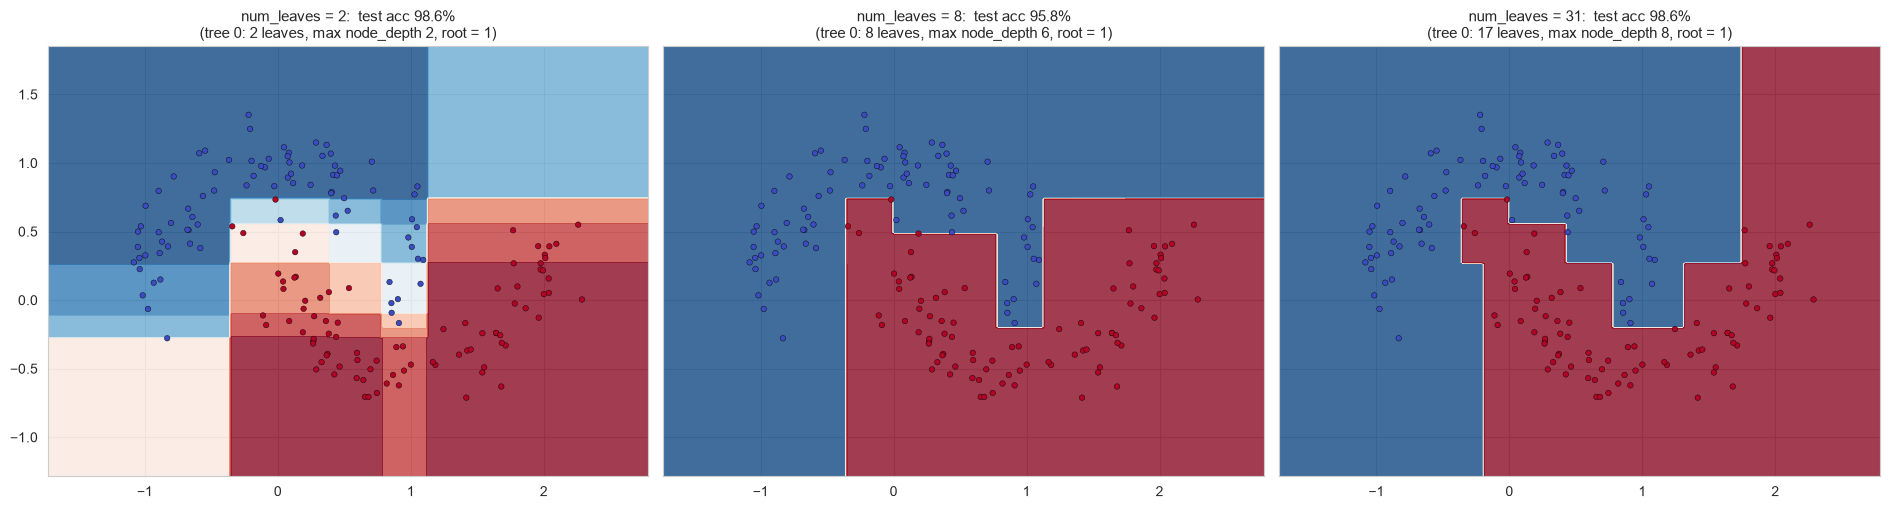

168 training rows; the default min_child_samples = 20 would cap every tree at
8 leaves - that is why the gate is explicitly relaxed above.

💡 num_leaves is a leaf BUDGET, spent greedily: 2 = one split per stage (a stump),
   8 = a compact balanced-ish shape, 31 = the default that wants several hundred
   rows per tree to mean anything. With min_child_samples = 1 the growth really
   reaches each budget - watch the second title line spend them asymmetrically.


In [2]:
# Three fits on the same moons split, differing ONLY in num_leaves
Xm_l, ym_l = make_moons(n_samples=240, noise=0.15, random_state=0)
Xml_tr, Xml_te, yml_tr, yml_te = train_test_split(Xm_l, ym_l, test_size=0.3, random_state=42)
n_train_l = len(Xml_tr)
min_rows_cap = n_train_l // 20   # min_child_samples=20 default would cap every tree here

budgets_l = [2, 8, 31]
lgb_models_l = []
for T_l in budgets_l:
    m_l = LGBMClassifier(num_leaves=T_l, n_estimators=100, learning_rate=0.1,
                         min_child_samples=1, verbosity=-1, random_state=42)
    lgb_models_l.append(m_l.fit(Xml_tr, yml_tr))

# How many leaves did tree 0 of each fit actually use? (structure read from the booster;
# in trees_to_dataframe a LEAF is the row with a null split_feature - split nodes carry one)
structs_l = []
for m_l in lgb_models_l:
    tdf_l = m_l.booster_.trees_to_dataframe()
    tree0_l = tdf_l[tdf_l["tree_index"] == 0]
    n_leaves_l = int(tree0_l["split_feature"].isna().sum())
    max_depth_l = int(tree0_l["node_depth"].max())
    structs_l.append((n_leaves_l, max_depth_l))

pad_l = 0.5
xx_l, yy_l = np.meshgrid(
    np.linspace(Xm_l[:, 0].min() - pad_l, Xm_l[:, 0].max() + pad_l, 220),
    np.linspace(Xm_l[:, 1].min() - pad_l, Xm_l[:, 1].max() + pad_l, 220),
)
grid_l = np.c_[xx_l.ravel(), yy_l.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), sharey=True)
for ax, m_l, T_l, (nv_l, dv_l) in zip(axes, lgb_models_l, budgets_l, structs_l):
    field_l = m_l.predict_proba(grid_l)[:, 1].reshape(xx_l.shape)
    ax.contourf(xx_l, yy_l, field_l, levels=np.linspace(0.0, 1.0, 11), cmap="RdBu_r", alpha=0.8)
    ax.scatter(Xml_tr[:, 0], Xml_tr[:, 1], c=yml_tr, cmap="coolwarm", s=16,
               edgecolors="k", linewidths=0.3)
    ax.set_title(f"num_leaves = {T_l:g}:  test acc {m_l.score(Xml_te, yml_te):.1%}"
                 f"\n(tree 0: {nv_l} leaves, max node_depth {dv_l}, root = 1)", fontsize=11)
plt.tight_layout()
plt.show()

print(f"{n_train_l} training rows; the default min_child_samples = 20 would cap every tree at")
print(f"{min_rows_cap} leaves - that is why the gate is explicitly relaxed above.")
print("\n💡 num_leaves is a leaf BUDGET, spent greedily: 2 = one split per stage (a stump),")
print("   8 = a compact balanced-ish shape, 31 = the default that wants several hundred")
print("   rows per tree to mean anything. With min_child_samples = 1 the growth really")
print("   reaches each budget - watch the second title line spend them asymmetrically.")

---

## 2. Theory & Mathematics

### The Same Objective, a Different Budget

Notebook 09's derivation carries over verbatim — at stage $m$ the loss is second-order Taylor-expanded around the current model, and each tree is grown against a complexity penalty:

$$\mathrm{Obj}^{(m)} = \sum_{i=1}^{n}\Big[\underbrace{\ell\big(y_i, \hat{y}_{m-1,i}\big)}_{\text{constant at stage } m} + \; g_i\, f_m(x_i) + \tfrac{1}{2}\,h_i\, f_m(x_i)^2\Big] + \Omega(f_m)$$

$$g_i = \frac{\partial\, \ell\big(y_i, \hat{y}\big)}{\partial \hat{y}}\bigg|_{\hat{y}_{m-1}} \qquad h_i = \frac{\partial^2\ell\big(y_i, \hat{y}\big)}{\partial \hat{y}^2}\bigg|_{\hat{y}_{m-1}} \qquad \Omega(f) = \gamma\, T + \tfrac{1}{2}\lambda \sum_{j} w_j^2$$

The stage losses are notebook 09's table unchanged (log-loss: $g = p - y$, $h = p(1-p)$; softmax: one tree per class, and LightGBM literally builds `num_class × num_iterations` trees for multiclass). Under squared error the first-order term is $F - y$ (verified in the shipped objective source — the same bookkeeping sign notebook 09 used for XGBoost, opposite the repo twin's $y - F$) with constant curvature $h = 1$, so every regression leaf value is just the (λ-smoothed) mean residual of its leaf.

Two default differences versus XGBoost, read directly from the pinned version's parameters:

1. **λ defaults to 0 here** (`reg_lambda = 0`, `reg_alpha = 0`) — XGBoost ships λ = 1. LightGBM's regularizer is opt-in; the leaf-data floors do the damping by default
2. **γ's job is same, packaging different**: `min_gain_to_split` is applied as a gate on the gain rather than a subtraction inside it — gain > toll vs. gain − toll > 0 is the same decision written twice

### From Gains to Tree Shape

Group the samples by leaf and complete the square per leaf — the same two closed forms notebook 09 derived, now the engine of a *growth policy*:

$$w_j^* = -\frac{G_j}{H_j + \lambda} \qquad \mathrm{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right]$$

with $G_j, H_j$ the (optionally row-weighted) gradient/hessian sums over leaf $j$. In LightGBM a candidate split must clear **three gates** before it happens:

| Gate | Parameter | Default | Blocks |
|---|---|---|---|
| a leaf may not be cut below this row count | `min_child_samples` (alias `min_data_in_leaf`) | 20 | tiny evidence-starved leaves |
| a leaf may not fall below this $\sum h$ | `min_child_weight` (alias `min_sum_hessian_in_leaf`) | 1e-3 | near-zero-curvature leaves |
| a split must earn more than this gain | `min_gain_to_split` (alias `min_split_gain`) | 0.0 | splits that don't pay |

The gain and the leaf values are the notebook-08 family invariant; **the growth policy is the LightGBM variable**:

| | Level-wise (notebooks 08–09, sklearn GBM) | Leaf-wise (LightGBM) |
|---|---|---|
| Frontier | all nodes of depth $d$, then $d+1$ | one global best-gain leaf per round |
| Shape | balanced | asymmetric, deep where signal lives |
| Complexity knob | `max_depth` | `num_leaves` |
| Likes | small proofs, steady depth caps | large data, many leaves |
| Risk | wastes budget on empty regions | with a big budget and small data, memorizes down one branch |

Two facts from the parameter reference of the pinned version pin the vocabulary:

- "`num_leaves` — max number of leaves in one tree" — with the constraint $1 < $ `num_leaves` $\le 131072$; the docs' tuning guide treats it as *the* first knob
- `max_depth` is **not** the growth template here — "...Tree still grows leaf-wise"; depth is a safety cap on the asymmetric growth (≤ 0 means no limit)

In [3]:
# One leaf's five training samples (the same numbers as notebook 08's Newton demo and
# notebook 09's lambda demo), now under LightGBM's reading: the gain is the growth currency
p_leaf = np.array([0.90, 0.20, 0.40, 0.70, 0.60])   # current probabilities
y_leaf = np.array([1.0, 1.0, 0.0, 1.0, 0.0])        # true labels

g_leaf = p_leaf - y_leaf               # first-order term: p - y
h_leaf = p_leaf * (1.0 - p_leaf)       # its curvature: p(1 - p)

G_leaf, H_leaf = g_leaf.sum(), h_leaf.sum()
print(f"leaf sums:  G = sum(g) = {G_leaf:+.4f}   H = sum(h) = {H_leaf:.4f}")

# The leaf value is the familiar Newton step, smoothed by lambda:
print()
for lam_l in [0.0, 1.0, 10.0]:
    w_l = -G_leaf / (H_leaf + lam_l)
    print(f"leaf value w* at lambda = {lam_l:5.1f}: {w_l:+.4f}")

# A candidate split separates rows [1, 2] (the uncertain pair) from rows [0, 3, 4]:
big_l = np.array([1, 2]); rest_l = np.array([0, 3, 4])
G_left = g_leaf[big_l].sum();  H_left = h_leaf[big_l].sum()
G_right = g_leaf[rest_l].sum(); H_right = h_leaf[rest_l].sum()
print(f"\ncandidate: left rows {big_l.tolist()}  (G={G_left:+.2f}, H={H_left:.2f}, "
      f"w*={-G_left / H_left:+.2f})")
print(f"           right rows {rest_l.tolist()} (G={G_right:+.2f}, H={H_right:.2f}, "
      f"w*={-G_right / H_right:+.2f})")
print()
for lam_l in [0.0, 10.0]:
    gain_l = 0.5 * (G_left**2 / (H_left + lam_l) + G_right**2 / (H_right + lam_l)
                    - G_leaf**2 / (H_leaf + lam_l))
    print(f"split gain at lambda = {lam_l:5.1f}: {gain_l:.4f}"
          f"   -> with min_gain_to_split = 0.1: "
          f"{'SPLIT' if gain_l > 0.1 else 'BLOCKED'}")

print("\n💡 Same leaf algebra as notebooks 08-09; where notebook 09 priced the split with")
print("   gamma - gamma INSIDE the gain formula, LightGBM writes the same decision as a")
print("   gate: the gain must clear min_gain_to_split. And the 'uncertain pair' carries")
print("   the curvature mass - leaf-wise growth will keep splitting exactly those leaves.")

leaf sums:  G = sum(g) = -0.2000   H = sum(h) = 0.9400

leaf value w* at lambda =   0.0: +0.2128
leaf value w* at lambda =   1.0: +0.1031
leaf value w* at lambda =  10.0: +0.0183

candidate: left rows [1, 2]  (G=-0.40, H=0.40, w*=+1.00)
           right rows [0, 3, 4] (G=+0.20, H=0.54, w*=-0.37)

split gain at lambda =   0.0: 0.2158   -> with min_gain_to_split = 0.1: SPLIT
split gain at lambda =  10.0: 0.0078   -> with min_gain_to_split = 0.1: BLOCKED

💡 Same leaf algebra as notebooks 08-09; where notebook 09 priced the split with
   gamma - gamma INSIDE the gain formula, LightGBM writes the same decision as a
   gate: the gain must clear min_gain_to_split. And the 'uncertain pair' carries
   the curvature mass - leaf-wise growth will keep splitting exactly those leaves.


### The Parameter Spelling Table: LightGBM ↔ XGBoost

The two parameter spellings from the wrapper and the native registry, side by side — the alias registry of the pinned version's parameters page is the translation table:

| Idea | LightGBM (wrapper parameter / native default) | XGBoost (notebook 09) | LightGBM native aliases |
|---|---|---|---|
| learning rate | `learning_rate` (0.1) | `learning_rate` / `eta` (0.3) | `eta`, `shrinkage_rate` |
| stage count | `n_estimators` (100) | `n_estimators` (100) | `num_iterations`, `num_boost_round` |
| **shape budget** | `num_leaves` (31) | — (depthwise) / `max_leaves` (lossguide) | `num_leaf`, `max_leaf_nodes` |
| shape cap | `max_depth` (−1 = none, *safety cap*) | `max_depth` (6, *growth template*) | — |
| leaf row floor | **`min_child_samples`** (20) | ~ `min_child_weight` in spirit (1) | `min_data_in_leaf`, `min_samples_leaf` |
| leaf hessian floor | `min_child_weight` (1e-3, Σ $h$) | `min_child_weight` (Σ $h$, 1) | `min_sum_hessian_in_leaf` |
| split toll | `min_split_gain` (0.0) | `gamma` (0.0, inside the gain) | `min_gain_to_split` |
| leaf L2 | `reg_lambda` (**0.0**) | `reg_lambda` (**1.0**) | `lambda_l2`, `lambda` |
| leaf L1 | `reg_alpha` (0.0) | `reg_alpha` (0.0) | `lambda_l1` |
| row sampler | `subsample` + `subsample_freq` (1.0 + **0** = off!) | `subsample` (1.0, active alone) | `bagging_fraction` + `bagging_freq` |
| column sampler | `colsample_bytree` (1.0) | `colsample_bytree` (1.0) | `feature_fraction` |
| importance default | `importance_type` = **split** | `importance_type` = **gain** | `split`, `gain`, totals |
| early stopping | `callbacks=[lgb.early_stopping(k)]` | constructor `early_stopping_rounds` | `early_stopping_round` |

Two rows carry migration warnings: the row sampler is **inert unless `subsample_freq` > 0** (the docs: "bagging is only effective when `bagging_freq > 0` and `bagging_fraction < 1.0`" — XGBoost's `subsample` alone has no such second key), and LightGBM's `min_child_weight` is the *hessian* floor — the row-count floor lives in `min_child_samples`.

---

## 3. Assumptions & Requirements

LightGBM inherits the tree base learner's distributional freedom, plus the boosting assumptions of notebooks 08–09 — and adds two headline features of its own.

### Critical Assumptions

#### ✅ 1. **No Feature Scaling Needed**
- Splits compare one feature against a threshold; monotone rescaling never changes an ordering
- **Contrast**: SVMs, KNN, and logistic regression all need scaling (notebooks 05–07); the whole tree family does not

#### ✅ 2. **Missing Values Routed Natively**
- NaNs in features are routed like any other value during the split search — the engine learns which branch they fit best, no imputation required (`zero_as_missing` stays `false` by default: 0 is data, NaN is missing)
- **Demo below**: the same NaN-corrupted breast-cancer matrix through both engines, versus the engines that refuse it
- **Caveat**: NaN in the **target** is an error everywhere; and when *serving* data gains NaNs the training data never had, an imputation pipeline is still the honest tool

#### ✅ 3. **Categorical Features Belong to the Engine** *(the headline assumption — the one LightGBM is famous for)*
- Pass pandas `category` dtype columns (or `categorical_feature` by name/index) and the split search partitions the category set directly — the docs' categorical guide describes the by-now-canonical trick: sort categories by their mean target/gradient, then treat the ordering like a numeric feature, so one split can express "any subset of tiers" instead of a one-hot forest
- Few categories (≤ `max_cat_to_onehot` = 4) fall back to one-vs-other splits; `cat_smooth` damps categories with few rows
- **Demo below**: one categorical feature, native handling vs pd.get_dummies one-hot, same data
- **Caveat**: high-cardinality categoricals on small data are still an overfitting machine — the gate `min_data_per_group = 100` and `cat_smooth = 10` exist for exactly that

#### ✅ 4. **The Loss Must Match the Task**
- The wrapper infers `objective` from the estimator class; a wrong metric for the decision still quietly optimizes the wrong quantity (logloss vs AUC vs accuracy — §7/§9)

#### ✅ 5. **Independent, Identically Distributed Rows**
- Stagewise chasing of residuals amplifies anything linking train to test rows (time drift, groups); time- or group-aware splits stay your job

#### ✅ 6. **Enough Rows for Meaningful Leaves**
- `min_child_samples = 20` is the *default expression of the law* here: on a few hundred rows the engine keeps cutting leaves short unless the gate is relaxed — a knob interplay the depth-wise engines express differently (notebook 03's `min_samples_leaf`, notebook 09's `min_child_weight`)
- Rule of thumb: from a few hundred rows on, boosted trees beat a tuned single tree; LightGBM starts preferring more rows than its depth-wise ancestors

### When Assumptions Are Violated

| Violation | Symptom | Fix |
|---|---|---|
| Noisy / mislabeled rows | Train accuracy → 1.0 while validation loss curls up | Early stopping; bagging; smaller `num_leaves`; add λ/α (§7) |
| Extrapolation required | Predictions clamp to the training range | Linear or Gaussian-process models |
| High-cardinality categoricals, few rows each | Validation loss far above train | `cat_smooth`, `min_data_per_group`, frequency/target-encode yourself |
| Heavy class imbalance | Good accuracy, bad minority recall | `class_weight="balanced"`, per-class metrics |
| Shuffled time series | Train rows resemble test rows from the future | Time-aware split; no shuffling |

rows in train: 426, cells set to NaN: 1311/12780
LightGBM on NaN train data:           test acc 95.8%  |  clean test acc 96.5%
HistGradientBoosting on NaN data:     test acc 96.5%
sklearn GradientBoostingClassifier:   ValueError - refuses NaN, imputation required


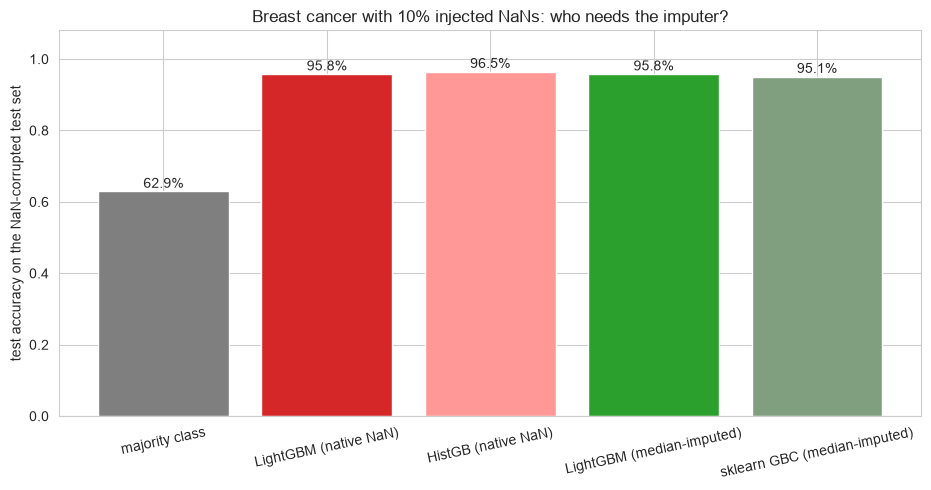


💡 Same verdict as notebook 09's XGBoost demo, one engine later: the histogram
   engines learn where NaNs belong instead of mailing them to an imputer. Set
   zero_as_missing = true only when 0 itself is a sentinel - by default it is data.


In [4]:
# The section 3 demo, part 1: NaN routing - LightGBM natively, its sklearn siblings beside it
bc_nan = load_breast_cancer()
Xbn_tr, Xbn_te, ybn_tr, ybn_te = train_test_split(
    bc_nan.data, bc_nan.target, test_size=0.25, stratify=bc_nan.target, random_state=42
)

# Inject 10% missingness - independently per cell, train and test
rng_nan = np.random.default_rng(0)
nan_mask_tr = rng_nan.random(Xbn_tr.shape) < 0.10
nan_mask_te = rng_nan.random(Xbn_te.shape) < 0.10
Xbn_tr_nan = Xbn_tr.copy()
Xbn_tr_nan[nan_mask_tr] = np.nan
Xbn_te_nan = Xbn_te.copy()
Xbn_te_nan[nan_mask_te] = np.nan
print(f"rows in train: {len(Xbn_tr)}, cells set to NaN: {nan_mask_tr.sum()}/{Xbn_tr.size}")

lgb_nan = LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=16,
                         verbosity=-1, random_state=42).fit(Xbn_tr_nan, ybn_tr)
hist_nan = HistGradientBoostingClassifier(max_depth=3, random_state=42).fit(Xbn_tr_nan, ybn_tr)

print(f"LightGBM on NaN train data:           test acc {lgb_nan.score(Xbn_te_nan, ybn_te):.1%}"
      f"  |  clean test acc {lgb_nan.score(Xbn_te, ybn_te):.1%}")
print(f"HistGradientBoosting on NaN data:     test acc {hist_nan.score(Xbn_te_nan, ybn_te):.1%}")

try:
    GradientBoostingClassifier(n_estimators=150).fit(Xbn_tr_nan, ybn_tr)
    print("sklearn GradientBoostingClassifier:   fitted (unexpected)")
except ValueError:
    print("sklearn GradientBoostingClassifier:   ValueError - refuses NaN, imputation required")

# Control rows: median imputation repairs the plain sklearn engine, and LightGBM itself
# barely changes - the routing is already the imputation that matters
lgb_imputed = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("lgb", LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=16,
                                               verbosity=-1, random_state=42))]).fit(Xbn_tr_nan, ybn_tr)
gbc_imputed = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("gb", GradientBoostingClassifier(n_estimators=150,
                                                          random_state=42))]).fit(Xbn_tr_nan, ybn_tr)

majority_nan = max(np.bincount(ybn_te)) / len(ybn_te)
rows_nan = [
    ("majority class", majority_nan),
    ("LightGBM (native NaN)", lgb_nan.score(Xbn_te_nan, ybn_te)),
    ("HistGB (native NaN)", hist_nan.score(Xbn_te_nan, ybn_te)),
    ("LightGBM (median-imputed)", lgb_imputed.score(Xbn_te_nan, ybn_te)),
    ("sklearn GBC (median-imputed)", gbc_imputed.score(Xbn_te_nan, ybn_te)),
]

fig, ax = plt.subplots(figsize=(9.5, 5))
labels_nan = [name_nan for name_nan, _ in rows_nan]
vals_nan = [v_nan for _, v_nan in rows_nan]
ax.bar(labels_nan, vals_nan, color=["#7f7f7f", "#d62728", "#ff9896", "#2ca02c", "#7f9f7f"])
for i_nan, v_nan in enumerate(vals_nan):
    ax.text(i_nan, v_nan + 0.01, f"{v_nan:.1%}", ha="center")
ax.set_ylim(0, 1.08)
ax.set_ylabel("test accuracy on the NaN-corrupted test set")
ax.set_title("Breast cancer with 10% injected NaNs: who needs the imputer?")
ax.tick_params(axis="x", labelrotation=12)
plt.tight_layout()
plt.show()

print("\n💡 Same verdict as notebook 09's XGBoost demo, one engine later: the histogram")
print("   engines learn where NaNs belong instead of mailing them to an imputer. Set")
print("   zero_as_missing = true only when 0 itself is a sentinel - by default it is data.")

Both engines took the corrupted matrix straight and lost almost nothing. The engine that needed the imputer is the one LightGBM rebuilt from. Missing-value routing is now table stakes for the histogram family — what LightGBM adds on top is the next demo: categories as first-class citizens.

### The Categorical Demo: native `category` dtype vs one-hot

Synthetic churn data, deliberately built the annoying way: one genuinely *discrete* feature whose per-tier churn effects are **not monotone in any ordering** (a "premium" tier can churn less than "basic" while "plus" churns more), two weak numeric features, one target. We compare the same `LGBMClassifier` fit on:

1. the **native path**: tier as a pandas `category` column, LightGBM partitions the category set itself
2. the **one-hot path**: `pd.get_dummies` — five binary columns compete for the same signal

categories seen natively: ['basic', 'free', 'partner', 'plus', 'premium']
one-hot columns:          ['tier_basic', 'tier_free', 'tier_partner', 'tier_plus', 'tier_premium']

                        native category    one-hot
test accuracy                     57.3%      58.0%
test logloss                     0.9335     0.9142

split count summed over the tier signal:  native 'tier' = 135   |   one-hot tier_* = 335


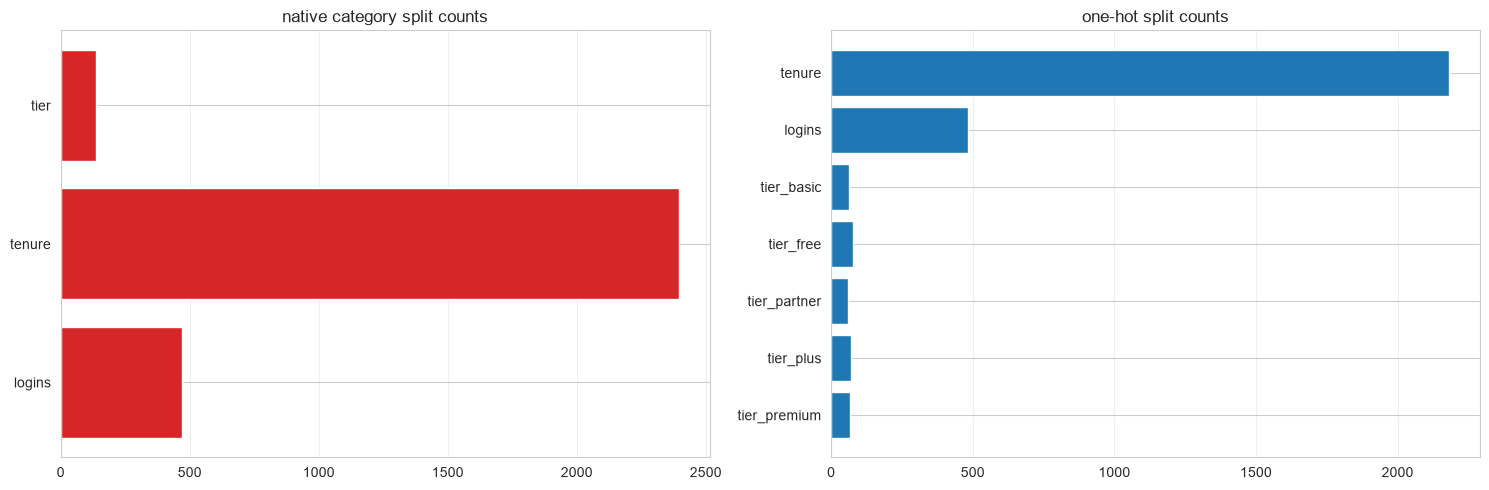


💡 LightGBM orders the categories by their mean target and splits the ORDERING
   like a numeric feature - one column, and the 'non-monotone' tier effects are
   reachable as a subset partition. One-hot spends a column per tier and needs
   several of them to carve the same partition - a signal chopped into competition.


In [5]:
# The section 3 demo, part 2: categories natively vs one-hot
rng_cat = np.random.default_rng(7)
n_cat = 600
tiers_cat = rng_cat.choice(["free", "basic", "plus", "premium", "partner"], n_cat,
                           p=[0.30, 0.25, 0.20, 0.18, 0.07])
tier_effect_cat = {"free": 0.45, "basic": -0.30, "plus": 0.35, "premium": -0.90, "partner": -1.20}
tenure_cat = rng_cat.exponential(14.0, n_cat)                      # months since signup
logins_cat = rng_cat.poisson(3, n_cat)                             # weekly logins

logit_cat = (np.array([tier_effect_cat[t] for t in tiers_cat])
             - 0.06 * tenure_cat + 0.40 * np.log1p(logins_cat)
             + rng_cat.normal(0.0, 0.55, n_cat))
churn_cat = (1.0 / (1.0 + np.exp(-logit_cat)) > rng_cat.random(n_cat)).astype(int)

Xcat_raw = pd.DataFrame({"tier": pd.Categorical(tiers_cat),   # <- the dtype IS the declaration
                         "tenure": tenure_cat, "logins": logins_cat})
Xcat_oh = pd.get_dummies(Xcat_raw, columns=["tier"], dtype=float)

Xcat_raw_tr, Xcat_raw_te = Xcat_raw.iloc[:450], Xcat_raw.iloc[450:]
Xcat_oh_tr, Xcat_oh_te = Xcat_oh.iloc[:450], Xcat_oh.iloc[450:]
ych_tr, ych_te = churn_cat[:450], churn_cat[450:]

common_cat = dict(n_estimators=200, learning_rate=0.1, num_leaves=16,
                  min_child_samples=10, verbosity=-1, random_state=42)
lgb_native_cat = LGBMClassifier(**common_cat).fit(Xcat_raw_tr, ych_tr)
lgb_onehot_cat = LGBMClassifier(**common_cat).fit(Xcat_oh_tr, ych_tr)

acc_native = accuracy_score(ych_te, lgb_native_cat.predict(Xcat_raw_te))
acc_onehot = accuracy_score(ych_te, lgb_onehot_cat.predict(Xcat_oh_te))
ll_native = log_loss(ych_te, lgb_native_cat.predict_proba(Xcat_raw_te))
ll_onehot = log_loss(ych_te, lgb_onehot_cat.predict_proba(Xcat_oh_te))

print(f"categories seen natively: {list(Xcat_raw['tier'].cat.categories)}")
print(f"one-hot columns:          {[c for c in Xcat_oh.columns if 'tier_' in c]}")
print()
print(f"{'':22s} {'native category':>16s} {'one-hot':>10s}")
print(f"{'test accuracy':22s} {acc_native:>16.1%} {acc_onehot:>10.1%}")
print(f"{'test logloss':22s} {ll_native:>16.4f} {ll_onehot:>10.4f}")

imp_native_cat = pd.Series(lgb_native_cat.feature_importances_, index=Xcat_raw.columns)
imp_oh_cat = pd.Series(lgb_onehot_cat.feature_importances_, index=Xcat_oh.columns)
tier_native = float(imp_native_cat["tier"])
tier_oh = float(imp_oh_cat[[c for c in Xcat_oh.columns if "tier_" in c]].sum())
print(f"\nsplit count summed over the tier signal:  native 'tier' = {tier_native:.0f}"
      f"   |   one-hot tier_* = {tier_oh:.0f}")

fig, axes_cat = plt.subplots(1, 2, figsize=(15, 5))
axes_cat[0].barh(imp_native_cat.index[::-1], imp_native_cat.values[::-1], color="#d62728")
axes_cat[0].set_title("native category split counts")
axes_cat[1].barh(imp_oh_cat.index[::-1], imp_oh_cat.values[::-1], color="#1f77b4")
axes_cat[1].set_title("one-hot split counts")
for ax_cat in axes_cat:
    ax_cat.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 LightGBM orders the categories by their mean target and splits the ORDERING")
print("   like a numeric feature - one column, and the 'non-monotone' tier effects are")
print("   reachable as a subset partition. One-hot spends a column per tier and needs")
print("   several of them to carve the same partition - a signal chopped into competition.")

Read the two panels together: the native engine spends its splits on `tier` as one column and keeps the numerics as numerics; the one-hot engine fragments the same signal across five columns, each one competing for the leaf budget, and on a non-monotone tier effect it needs several of them to reconstruct what a single partition expressed natively. That economy — not raw accuracy on every dataset — is why LightGBM is the default engine on wide, sparse, categorical-heavy tabular data.

Fewer than 5 categories and the engine switches to one-vs-other splits (`max_cat_to_onehot`), which is what the default path does anyway. High cardinality with few rows per category is where it gets what it pays for: `cat_smooth = 10` and `min_data_per_group = 100` keep the ordering statistic from overfitting single noisy categories.

---

## 4. When to Use This Algorithm

### ✅ Use LightGBM When:

1. **The dataset is genuinely large and speed is the product**
   - Histogram bins, GOSS row sampling, and EFB column bundling are the paper's own contributions for exactly this regime
2. **Wide, sparse, or categorical-heavy feature spaces**
   - Native `category` dtype, exclusive feature bundling, and no imputer for NaN features
3. **Momentum matters more than a long tuning session**
   - `LGBMClassifier` at ~defaults is usually already competitive; the leaf budget is the one knob that must move (`num_leaves`, guided by `min_child_samples`)
4. **Regression on structured data too**
   - `LGBMRegressor` with the same engines; objectives from L1 to quantile, Poisson
5. **Probability-like outputs on decision-critical tasks**
   - The same verification as notebook 08/09's Example 1: histogram + Brier score before decisions (§10)

### ❌ Avoid LightGBM When:

1. **Tiny datasets (a few hundred rows or fewer)**
   - `num_leaves=31` and `min_child_samples=20` fight each other on small data; a linear model or pruned single tree is steadier (notebooks 01–03)
2. **Extrapolation is required**
   - Trees clamp to the training range; nothing boosted extrapolates (§10 Example 2)
3. **A small, audit-friendly model must be deployed**
   - Leaf budgets build deep asymmetric forests; when every leaf must be named and walked, notebook 03's single tree is inspectable and a boosted ensemble is not
4. **You need calibrated probabilities with no verification step**
    - Confident-but-wrong is the failure mode of any boosted probability; check reliability with the Brier read before decisions (§10)
5. **Text/image-adjacent unstructured data**
   - Representation learning owns that world (notebook 17)

### Classification vs Regression

| | Classification | Regression |
|---|---|---|
| Estimator | `LGBMClassifier` | `LGBMRegressor` |
| Default objective | auto: binary / multiclass (softmax) | auto: squared error (`regression`) |
| $g_i$, $h_i$ | $p - y$; $p(1-p)$ (per class, softmax) | $F - y$; $1$ (regression, off the shipped objective source) |
| Trees per stage | 1 (binary), K (multiclass) | 1 |
| Multi-class note | LightGBM constructs `num_class × num_iterations` trees | — |
| Native labels | any (wrapper LabelEncodes) | any |
| Stage budget | `n_estimators` = `num_iterations` | same |
| From-scratch twin | family twin `GradientBoostingClassifierScratch` (§5) | none — library-only (§6) |

---

## 5. Implementation from Scratch (NumPy)

### Why Hands-On, When LightGBM Itself Is Compiled?

LightGBM *the library* is a compiled C++/OpenMP system — the repo does not (and should not) re-implement that part. What the repo does implement is the **gradient boosting skeleton** both XGBoost and LightGBM build on: `GradientBoostingClassifierScratch` in `src/models/ensemble_models.py`, the notebook-08 twin with its Newton leaf values (notebook 09 showed `_newton_leaf_values` is exactly $w^* = -G/(H+\lambda)$ at λ = 0).

Section 5 uses that twin as the reference point and hand-builds LightGBM's two defining moves on top of it:

1. **A gain-priced tree grower** — LightGBM's own loop, in NumPy: per-node gradient/hessian sums, the λ-smoothed gain of §2 pricing every candidate cut, the three gates applied, leaf values $w^* = -G/(H+\lambda)$ — with **both growth policies sharing one code path** so level-vs-leaf becomes a controlled experiment, not a folklore claim
2. **A GOSS boosting loop** — keep every big-gradient row, random-sample the small-gradient remainder at `other_rate`, reweight it by $(1-a)/b$ — the hand version of `data_sample_strategy="goss"`

What is deliberately **not** hand-built here: the histogram bin construction (`max_bin`), exclusive feature bundling (EFB), the native categorical partitioning, and the C++/OpenMP execution. Those coordinates get discussed where they matter (§3, §6, §8) but never re-computed.

In [6]:
# Import the family twin (the gradient boosting skeleton behind LightGBM)
import sys
sys.path.append('../src')

from models.ensemble_models import GradientBoostingClassifierScratch
from models.tree_models import DecisionTreeRegressorScratch

print("✅ Imported the family twin from src/models/ensemble_models.py!")
print("\nWhat the twin provides (guided in notebooks 08/09, section 5 there):")
print("  • GradientBoostingClassifierScratch: stagewise additive model on log-loss /")
print("    softmax deviance with Newton leaf values sum(g)/sum(h) - the lambda = 0 leaf algebra")
print("  • DecisionTreeRegressorScratch: the regression tree each stage fits to residuals")
print("\nWhat notebook 10 hand-builds on top of it (the LightGBM-specific moves):")
print("  • grow_tree_gain: splits priced on the gain formula itself, three gates, both")
print("    growth policies (level / leaf) on one code path, leaves w* = -G/(H + lambda)")
print("  • the GOSS sampling loop (top_rate / other_rate with (1-a)/b reweighting)")
print("\nWhat is NOT re-implemented (LightGBM's compiled engine handles these):")
print("  • histogram bins (max_bin), exclusive feature bundling (EFB), native categorical")
print("    partitions, and the C++/OpenMP execution paths")

✅ Imported the family twin from src/models/ensemble_models.py!

What the twin provides (guided in notebooks 08/09, section 5 there):
  • GradientBoostingClassifierScratch: stagewise additive model on log-loss /
    softmax deviance with Newton leaf values sum(g)/sum(h) - the lambda = 0 leaf algebra
  • DecisionTreeRegressorScratch: the regression tree each stage fits to residuals

What notebook 10 hand-builds on top of it (the LightGBM-specific moves):
  • grow_tree_gain: splits priced on the gain formula itself, three gates, both
    growth policies (level / leaf) on one code path, leaves w* = -G/(H + lambda)
  • the GOSS sampling loop (top_rate / other_rate with (1-a)/b reweighting)

What is NOT re-implemented (LightGBM's compiled engine handles these):
  • histogram bins (max_bin), exclusive feature bundling (EFB), native categorical
    partitions, and the C++/OpenMP execution paths


### The Gain-Priced Grower (Hand-Built)

One tree of one stage, built LightGBM's way:

1. $F_0$: the log-odds of the positive class's base rate — the twin's `_f0_logit`; LightGBM computes the same constant from the labels (`boost_from_average` initialization)
2. Compute $g_i = p_i - y_i$ and $h_i = p_i(1 - p_i)$ fresh from the current $F$
3. **Grow on the gain formula, not on residual least squares**: every node carries its $(G, H)$; for each feature, midpoints between consecutive sorted values are the candidate cuts; the λ-smoothed gain of §2 prices each one; the three gates (`min rows`, `min hessian`, `min gain`) veto candidates
4. **Spend the leaf budget**: which leaf splits next is the policy — level-wise sweeps the current depth level before going deeper; leaf-wise always pops the single best-gain leaf from the whole frontier
5. Every terminal leaf takes $w^* = -G/(H+\lambda)$, and the stage add is $F \leftarrow F + \nu \cdot \mathrm{tree}(x)$ — shrinkage exactly once

Step 4 is the notebook's handle: **one grower, two policies, same data, same candidate grid, same gates** — the level-vs-leaf comparison below isolates the policy.

In [7]:
# The gain-priced grower: LightGBM's growth machinery, hand-built in NumPy
def grow_tree_gain(X_fit, g, h, w, lam=0.0, num_leaves=8, policy="leaf",
                   depth_cap=-1, min_rows=1, min_hess=0.0, min_gain=0.0):
    # Gain-priced tree growth on the (g, h) tensors - LightGBM's loop, in NumPy.
    # policy="leaf":  pop the best-gain open leaf every round (leaf-wise)
    # policy="level": sweep the current depth level before going deeper; when the
    #                 budget binds, highest-gain first (a teaching hybrid)
    X_fit = np.asarray(X_fit, dtype=float)
    n_fit, d_fit = X_fit.shape

    def make_node(idx, depth):
        G = float((w[idx] * g[idx]).sum())
        H = float((w[idx] * h[idx]).sum())
        node = {"idx": idx, "depth": depth, "G": G, "H": H, "w": 0.0,
                "gain": 0.0, "split": None, "left": None, "right": None}
        best_gain, best = 0.0, None
        for f in range(d_fit):
            vals = X_fit[idx, f]
            order = np.argsort(vals, kind="mergesort")
            xs = vals[order]
            gw = (w[idx] * g[idx])[order]
            hw = (w[idx] * h[idx])[order]
            cg = np.concatenate(([0.0], np.cumsum(gw)))   # cg[k] = weighted sum of first k rows
            ch = np.concatenate(([0.0], np.cumsum(hw)))
            m = len(idx)
            cuts = np.nonzero(xs[:-1] != xs[1:])[0]       # cut after position c: left = c+1 rows
            left_rows = cuts + 1
            ok = (left_rows >= min_rows) & ((m - left_rows) >= min_rows)
            if not ok.any() or (depth_cap >= 0 and depth + 1 > depth_cap):
                continue
            pos = cuts[ok] + 1
            GL, HL = cg[pos], ch[pos]
            GR, HR = G - GL, H - HL
            gains = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam)
                           - G**2 / (H + lam))
            gates = (HL >= min_hess) & (HR >= min_hess) & (gains > min_gain)
            if not gates.any():
                continue
            k_choice = int(np.where(gates)[0][np.argmax(gains[gates])])
            if gains[k_choice] > best_gain:
                best_gain = float(gains[k_choice])
                best = (f, float((xs[pos[k_choice] - 1] + xs[pos[k_choice]]) / 2.0))
        node["gain"] = best_gain
        node["split"] = best
        return node

    def split_node(node):
        f_split, thr = node["split"]
        lm = X_fit[node["idx"], f_split] <= thr
        node["left"] = make_node(node["idx"][lm], node["depth"] + 1)
        node["right"] = make_node(node["idx"][~lm], node["depth"] + 1)

    root = make_node(np.arange(n_fit), 0)
    open_leaves = [root]
    # identity-based removal everywhere: list.remove() falls back to dict __eq__ when
    # scanning items, and dict __eq__ compares the "idx" NumPy arrays - two sibling
    # nodes with different row counts would raise a broadcasting error mid-scan.
    # `v is not node` sidesteps the comparison entirely.
    if policy == "leaf":
        while len(open_leaves) < num_leaves:
            candidates = [v for v in open_leaves if v["split"] is not None]
            if not candidates:
                break
            node = max(candidates, key=lambda v: v["gain"])
            split_node(node)
            open_leaves = [v for v in open_leaves if v is not node]
            open_leaves.extend([node["left"], node["right"]])
    else:
        level = open_leaves
        while level:
            next_level = []
            for node in sorted([v for v in level if v["split"] is not None],
                               key=lambda v: -v["gain"]):
                if len(open_leaves) >= num_leaves:
                    break
                split_node(node)
                open_leaves = [v for v in open_leaves if v is not node]
                open_leaves.extend([node["left"], node["right"]])
                next_level.extend([node["left"], node["right"]])
            level = next_level
    for v_leaf in open_leaves:
        v_leaf["w"] = -v_leaf["G"] / max(v_leaf["H"] + lam, 1e-12)   # leaf value, lambda-smoothed
    return root, open_leaves


def gain_tree_predict(root, X_eval):
    out = np.zeros(len(X_eval))

    def walk(node, mask):
        if node["left"] is None:
            out[mask] = node["w"]
            return
        f_walk, thr_walk = node["split"]
        lm = mask & (X_eval[:, f_walk] <= thr_walk)
        walk(node["left"], lm)
        walk(node["right"], mask & ~lm)

    walk(root, np.ones(len(X_eval), dtype=bool))
    return out


def gain_leaf_depths(root):
    depths = []

    def walk(node):
        if node["left"] is None:
            depths.append(node["depth"])
            return
        walk(node["left"])
        walk(node["right"])

    walk(root)
    return np.asarray(depths)


print("✅ grower ready: one code path, two policies (leaf / level), gain-priced splits,")
print("   gates (min_rows, min_hess, min_gain), leaves w* = -G/(H + lambda).")

✅ grower ready: one code path, two policies (leaf / level), gain-priced splits,
   gates (min_rows, min_hess, min_gain), leaves w* = -G/(H + lambda).


In [8]:
# The boosting loop around the hand-built grower (same staging as notebooks 08/09)
NU_HAND, STAGES_HAND = 0.1, 40

Xm5, ym5 = make_moons(n_samples=240, noise=0.15, random_state=0)
Xm5_tr, Xm5_te, ym5_tr, ym5_te = train_test_split(Xm5, ym5, test_size=0.3, random_state=42)


def goss_boost(X_fit, y01, n_stages_spin, nu_spin, num_leaves_spin, policy_spin="leaf",
               lam_spin=0.0, goss_spin=None, seed_spin=0, **spin_kwargs):
    # The staged skeleton around grow_tree_gain. goss_spin = None -> full batch per stage,
    # otherwise (top_rate, other_rate): GOSS row sampling + reweighting, fresh per stage.
    n_spin = len(X_fit)
    y_arr = np.asarray(y01, dtype=float)
    pos_rate = float(np.clip((y_arr == 1).mean(), 1e-15, 1 - 1e-15))
    f0_spin = float(np.log(pos_rate / (1 - pos_rate)))      # F0: the same base-rate constant
    F_spin = np.full(n_spin, f0_spin)
    trees_spin, rows_spin = [], []
    rng_spin = np.random.default_rng(seed_spin)
    for _ in range(n_stages_spin):
        p_spin = 1.0 / (1.0 + np.exp(-np.clip(F_spin, -30.0, 30.0)))
        g_spin = p_spin - y_arr                             # first-order term
        h_spin = p_spin * (1.0 - p_spin)                    # second-order term
        if goss_spin is None:
            idx_spin, w_spin = np.arange(n_spin), np.ones(n_spin)
        else:
            top_rate, other_rate = goss_spin
            n_big = int(round(n_spin * top_rate))
            big_idx = np.argsort(-np.abs(g_spin))[:n_big]   # large-gradient rows: kept
            rest_idx = np.setdiff1d(np.arange(n_spin), big_idx)
            n_small = int(round(n_spin * other_rate))
            small_idx = rng_spin.choice(rest_idx, size=min(n_small, len(rest_idx)),
                                        replace=False)
            idx_spin = np.concatenate([big_idx, small_idx])
            w_spin = np.ones(len(idx_spin))
            w_spin[len(big_idx):] = (1.0 - top_rate) / other_rate   # GOSS reweighting
        tree_spin, _ = grow_tree_gain(X_fit[idx_spin], g_spin[idx_spin], h_spin[idx_spin],
                                      w_spin, lam=lam_spin, num_leaves=num_leaves_spin,
                                      policy=policy_spin, **spin_kwargs)
        rows_spin.append(len(idx_spin))
        F_spin = F_spin + nu_spin * gain_tree_predict(tree_spin, X_fit)
        trees_spin.append(tree_spin)
    return f0_spin, trees_spin, rows_spin


def boost_proba(X_eval, f0_spin, trees_spin, nu_spin=NU_HAND):
    F = np.full(len(X_eval), f0_spin)
    for tr_spin in trees_spin:
        F = F + nu_spin * gain_tree_predict(tr_spin, X_eval)
    return 1.0 / (1.0 + np.exp(-np.clip(F, -30.0, 30.0)))


# Stage-1 reference check against the family twin: one stage, budget 8, lambda = 0.
# The shared skeleton (F0, fresh g/h, Newton leaves) is guaranteed to agree; the trees
# will not, because the twin fits residuals by least squares and this grower prices the
# splits on the gain itself - which is precisely LightGBM's divergence from notebook 08.
f0_check, trees_check, _ = goss_boost(Xm5_tr, ym5_tr, 1, NU_HAND, 8, policy_spin="level")
p_hand = boost_proba(Xm5_tr, f0_check, trees_check)
twin_check = GradientBoostingClassifierScratch(n_estimators=1, learning_rate=NU_HAND,
                                               max_depth=3).fit(Xm5_tr, ym5_tr)
p_twin = twin_check.predict_proba(Xm5_tr)[:, 1]
print(f"F0 agrees:  {np.isclose(f0_check, twin_check._f0_logit)}"
      f"  (log-odds of the positive base rate, computed identically)")
mean_dp_check = np.abs(p_hand - p_twin).mean()
agree_check = np.mean((p_hand >= 0.5) == (p_twin >= 0.5))
print(f"stage-1 hand engine vs twin:  mean |dp| = {mean_dp_check:.4f} | "
      f"label agreement = {agree_check:.1%} | "
      f"train acc {np.mean((p_hand >= 0.5) == ym5_tr):.1%} vs "
      f"{np.mean((p_twin >= 0.5) == ym5_tr):.1%}")
print("\n💡 Same skeleton, different split criterion: the shared pieces (F0, Newton")
print("   leaves, shrinkage, staged replay) are identical by construction; the trees")
print("   differ because LightGBM prices candidates on the gain formula instead of")
print("   residual least squares.")

F0 agrees:  True  (log-odds of the positive base rate, computed identically)
stage-1 hand engine vs twin:  mean |dp| = 0.0033 | label agreement = 100.0% | train acc 93.5% vs 93.5%

💡 Same skeleton, different split criterion: the shared pieces (F0, Newton
   leaves, shrinkage, staged replay) are identical by construction; the trees
   differ because LightGBM prices candidates on the gain formula instead of
   residual least squares.


policy        leaf   level
num_leaves                
2           0.2470  0.2470
4           0.0658  0.1367
8           0.0362  0.0487
16          0.0748  0.0100
32          0.0748  0.0748



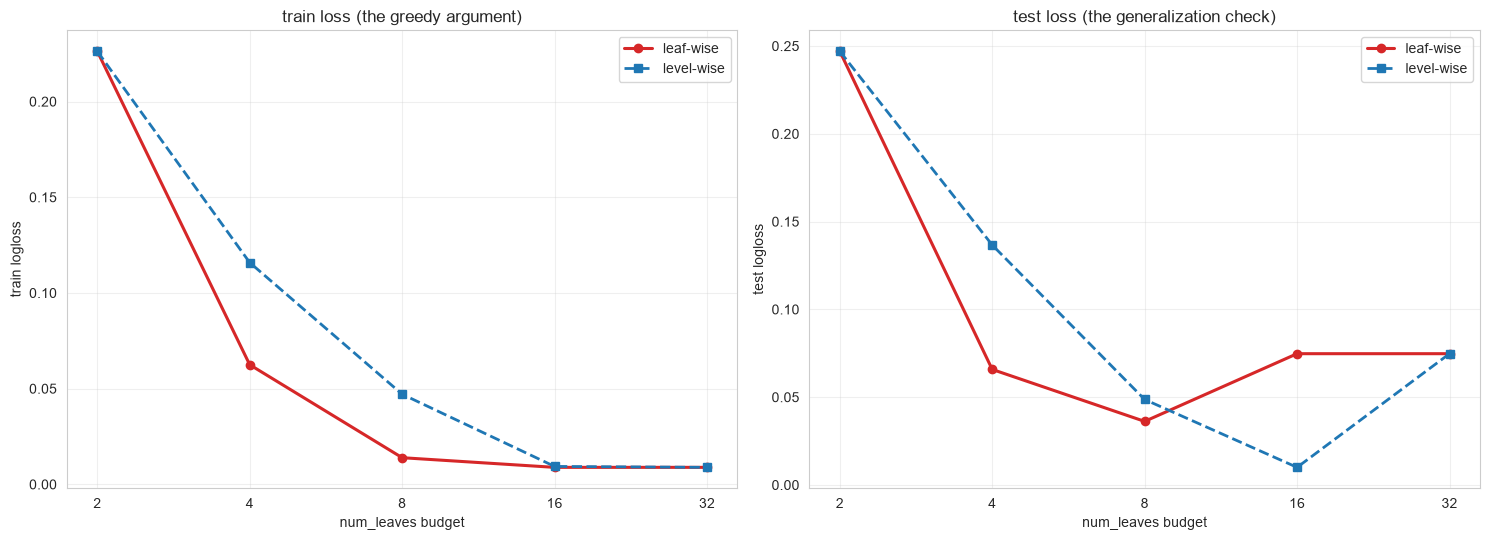

at the budget of 16 leaves: leaf-wise train loss 0.0089  vs  level-wise 0.0094   (one measured run)

💡 The greedy frontier spends every leaf where the gain is highest, so leaf-wise
   bends train loss down faster at each budget. The test panel is the honesty check:
   the budget that wins train can overfit - which is exactly why LightGBM leans on
   the leaf floors (min_child_samples) instead of a depth template.


In [9]:
# The level-vs-leaf sweep: same data, same candidates, same gates - only the policy moves
budgets_pol = [2, 4, 8, 16, 32]
rows_pol = []
for B_pol in budgets_pol:
    for pol_sel in ["level", "leaf"]:
        f0_pol, trees_pol, _ = goss_boost(Xm5_tr, ym5_tr, STAGES_HAND, NU_HAND,
                                          B_pol, policy_spin=pol_sel)
        ll_tr_pol = log_loss(ym5_tr, boost_proba(Xm5_tr, f0_pol, trees_pol))
        ll_te_pol = log_loss(ym5_te, boost_proba(Xm5_te, f0_pol, trees_pol))
        acc_te_pol = accuracy_score(ym5_te, boost_proba(Xm5_te, f0_pol, trees_pol) >= 0.5)
        rows_pol.append({"num_leaves": B_pol, "policy": pol_sel,
                         "train logloss": ll_tr_pol, "test logloss": ll_te_pol,
                         "test acc": acc_te_pol})

df_pol = pd.DataFrame(rows_pol)
print(df_pol.pivot(index="num_leaves", columns="policy", values="test logloss")
      .round(4).to_string())
print()

fig, axes_pol = plt.subplots(1, 2, figsize=(15, 5.5))
for ax_pol, metric_pol, title_pol in zip(axes_pol, ["train logloss", "test logloss"],
                                         ["train loss (the greedy argument)",
                                          "test loss (the generalization check)"]):
    pivot_pol = df_pol.pivot(index="num_leaves", columns="policy", values=metric_pol)
    ax_pol.plot(pivot_pol.index, pivot_pol["leaf"], "o-", color="#d62728", lw=2.2,
                label="leaf-wise")
    ax_pol.plot(pivot_pol.index, pivot_pol["level"], "s--", color="#1f77b4", lw=2,
                label="level-wise")
    ax_pol.set_xscale("log", base=2)
    ax_pol.set_xticks(budgets_pol, [str(b_pol) for b_pol in budgets_pol])
    ax_pol.set_xlabel("num_leaves budget")
    ax_pol.set_ylabel(metric_pol)
    ax_pol.set_title(title_pol)
    ax_pol.legend()
    ax_pol.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

pair16_pol = df_pol[df_pol["num_leaves"] == 16].set_index("policy")
print(f"at the budget of 16 leaves: leaf-wise train loss {pair16_pol.loc['leaf', 'train logloss']:.4f}"
      f"  vs  level-wise {pair16_pol.loc['level', 'train logloss']:.4f}   (one measured run)")
print("\n💡 The greedy frontier spends every leaf where the gain is highest, so leaf-wise")
print("   bends train loss down faster at each budget. The test panel is the honesty check:")
print("   the budget that wins train can overfit - which is exactly why LightGBM leans on")
print("   the leaf floors (min_child_samples) instead of a depth template.")

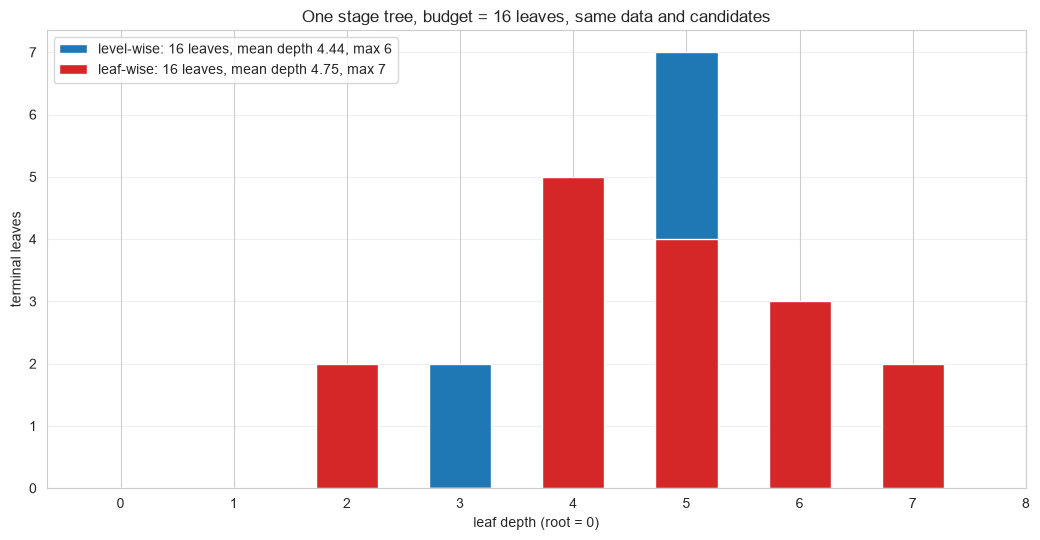

level-wise leaf depths: min 2, max 6, spread 4
leaf-wise  leaf depths: min 2, max 7, spread 5

💡 An equal leaf budget, spent differently: level-wise parks its leaves at
   nearly uniform depth; leaf-wise goes deep where the residuals are steep and
   shallow where the data is already clean. That asymmetry is the whole trick -
   and the reason a depth cap (max_depth) is a safety valve here, not the design.


In [10]:
# The shape story: one stage tree at the same budget, level vs leaf
B_shape = 16
shape_moons = make_moons(n_samples=240, noise=0.15, random_state=0)
Xsh_tr, _, ysh_tr, _ = train_test_split(shape_moons[0], shape_moons[1],
                                        test_size=0.3, random_state=42)

f0_lvl, trees_lvl, _ = goss_boost(Xsh_tr, ysh_tr, 1, NU_HAND, B_shape, policy_spin="level")
f0_leaf, trees_leaf, _ = goss_boost(Xsh_tr, ysh_tr, 1, NU_HAND, B_shape, policy_spin="leaf")
depths_lvl, depths_leaf = gain_leaf_depths(trees_lvl[0]), gain_leaf_depths(trees_leaf[0])

fig, ax_sh = plt.subplots(figsize=(10.5, 5.5))
bins_sh = range(0, int(max(depths_lvl.max(), depths_leaf.max())) + 2)
ax_sh.hist(depths_lvl, bins=bins_sh, align="left", rwidth=0.55, color="#1f77b4",
           label=f"level-wise: {len(depths_lvl)} leaves, mean depth {depths_lvl.mean():.2f}, "
                 f"max {depths_lvl.max()}")
ax_sh.hist(depths_leaf, bins=bins_sh, align="left", rwidth=0.55, color="#d62728",
           label=f"leaf-wise: {len(depths_leaf)} leaves, mean depth {depths_leaf.mean():.2f}, "
                 f"max {depths_leaf.max()}")
ax_sh.set_xticks(bins_sh)
ax_sh.set_xlabel("leaf depth (root = 0)")
ax_sh.set_ylabel("terminal leaves")
ax_sh.set_title(f"One stage tree, budget = {B_shape} leaves, same data and candidates")
ax_sh.legend()
ax_sh.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"level-wise leaf depths: min {depths_lvl.min()}, max {depths_lvl.max()}, "
      f"spread {depths_lvl.max() - depths_lvl.min()}")
print(f"leaf-wise  leaf depths: min {depths_leaf.min()}, max {depths_leaf.max()}, "
      f"spread {depths_leaf.max() - depths_leaf.min()}")
print("\n💡 An equal leaf budget, spent differently: level-wise parks its leaves at")
print("   nearly uniform depth; leaf-wise goes deep where the residuals are steep and")
print("   shallow where the data is already clean. That asymmetry is the whole trick -")
print("   and the reason a depth cap (max_depth) is a safety valve here, not the design.")

               stage data  rows / stage  train logloss  test logloss  test acc
   full batch (top = 1.0)         168.0         0.0089        0.0748    0.9861
goss (top 0.2, other 0.1)          51.0         0.0128        0.0298    1.0000
goss (top 0.4, other 0.2)         101.0         0.0094        0.0224    0.9861
goss (top 0.6, other 0.3)         151.0         0.0089        0.0492    0.9861



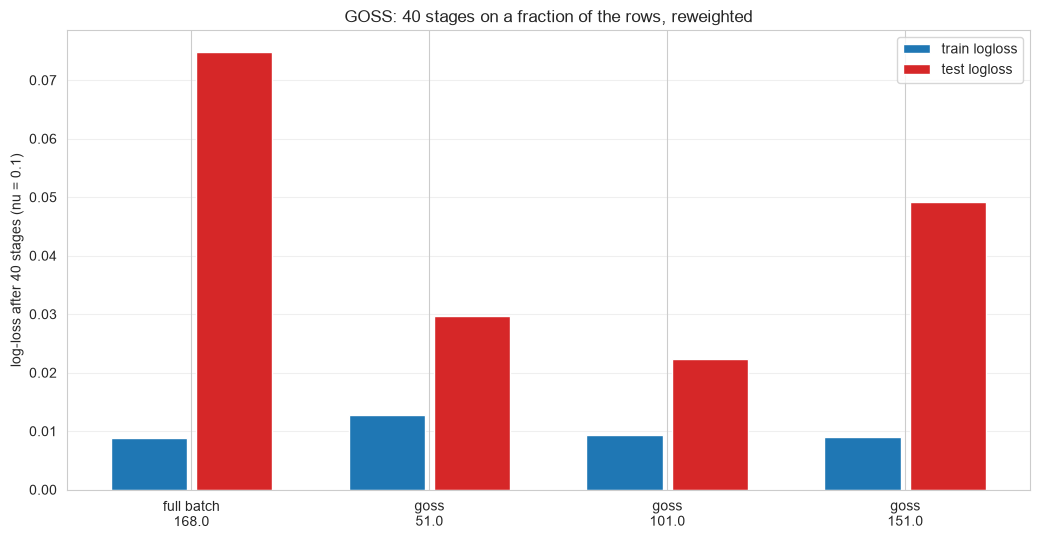

the (0.2, 0.1) setting fits each stage on ~51 of 168 rows (30%): every large-gradient row survives, and the
sampled small-gradient rows are reweighted by (1 - 0.2) / 0.1 = 8.0 to restore
the true gradient/hessian mass the sampler dropped.

💡 GOSS prices its shortcut: the hard rows always stay, the easy ones are sampled
   and paid back in weight. Train loss gives up a little, test loss is close to
   the full-batch fit - the paper's argument is speed at scale, not free accuracy.
   (The reweighted sums are the same w = -G/(H + lambda) machinery, one more
   reading of the weights column: the stage's G, H are WEIGHTED sums.)


In [11]:
# The GOSS hand-loop: same engine, but the stage fits run on sampled + reweighted rows
goss_configs = {"full batch (top = 1.0)": None,
                "goss (top 0.2, other 0.1)": (0.2, 0.1),
                "goss (top 0.4, other 0.2)": (0.4, 0.2),
                "goss (top 0.6, other 0.3)": (0.6, 0.3)}
rows_goss = []
for name_goss, cfg_goss in goss_configs.items():
    f0_goss, trees_goss, rows_used = goss_boost(Xm5_tr, ym5_tr, STAGES_HAND, NU_HAND,
                                                16, policy_spin="leaf", goss_spin=cfg_goss,
                                                seed_spin=0)
    p_tr = boost_proba(Xm5_tr, f0_goss, trees_goss)
    p_te = boost_proba(Xm5_te, f0_goss, trees_goss)
    rows_goss.append({"stage data": name_goss,
                      "rows / stage": float(np.mean(rows_used)),
                      "train logloss": log_loss(ym5_tr, p_tr),
                      "test logloss": log_loss(ym5_te, p_te),
                      "test acc": accuracy_score(ym5_te, p_te >= 0.5)})

df_goss = pd.DataFrame(rows_goss)
print(df_goss.round(4).to_string(index=False))
print()

fig, ax_goss = plt.subplots(figsize=(10.5, 5.5))
xs_goss = np.arange(len(df_goss))
ax_goss.bar(xs_goss - 0.18, df_goss["train logloss"], width=0.32, color="#1f77b4",
            label="train logloss")
ax_goss.bar(xs_goss + 0.18, df_goss["test logloss"], width=0.32, color="#d62728",
            label="test logloss")
ax_goss.set_xticks(xs_goss, [f"{name_goss.split(' (')[0]}\n{part_goss}"
                            for name_goss, part_goss in
                            zip(df_goss["stage data"],
                                [str(r) for r in df_goss["rows / stage"].round(0)])])
ax_goss.set_ylabel("log-loss after 40 stages (nu = 0.1)")
ax_goss.set_title("GOSS: 40 stages on a fraction of the rows, reweighted")
ax_goss.legend()
ax_goss.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

n_rows_goss = df_goss["rows / stage"].iloc[1]
print(f"the (0.2, 0.1) setting fits each stage on ~{n_rows_goss:.0f} of {len(Xm5_tr)} rows "
      f"({n_rows_goss / len(Xm5_tr):.0%}): every large-gradient row survives, and the")
print(f"sampled small-gradient rows are reweighted by (1 - 0.2) / 0.1 = 8.0 to restore")
print(f"the true gradient/hessian mass the sampler dropped.")
print("\n💡 GOSS prices its shortcut: the hard rows always stay, the easy ones are sampled")
print("   and paid back in weight. Train loss gives up a little, test loss is close to")
print("   the full-batch fit - the paper's argument is speed at scale, not free accuracy.")
print("   (The reweighted sums are the same w = -G/(H + lambda) machinery, one more")
print("   reading of the weights column: the stage's G, H are WEIGHTED sums.)")

### How the Family Twin Works, and What LightGBM Adds

Read `src/models/ensemble_models.py` alongside these facts (notebook 08's tour, notebook 09's bridge):

**1. The initial guess $F_0$ is a base rate, both in the twin and in LightGBM (`boost_from_average`).**
The twin stores $F_0 = \log\frac{r}{1-r}$ for the positive class's base rate $r$ (clipped away from 0/1) as `_f0_logit`. LightGBM computes its treeless initial score from the labels the same way.

**2. $g$ and $h$ are recomputed fresh from the current $F$ at every stage (`fit`).**
Identity of assembly across all three engines — the gradient is what changes, never the staging.

**3. Stage trees' leaves are Newton values (`_newton_leaf_values`).**
The twin's classmethod regroups rows by leaf via the tree's `apply` accessor and overwrites each leaf with $\sum g / \max(\sum h, 10^{-12})$ — precisely LightGBM's $w^* = -G/(H+\lambda)$ **at λ = 0**. The hand grower's steps 3–5 carry the λ all the way.

**4. Shrinkage is applied exactly once per stage (`fit`).**
$F \leftarrow F + \nu\, h_m$; the raw tree output is never added unscaled. `estimators_` records each stage's trees (binary: one; multiclass: one per class).

**5. Prediction replays the stages (`_decision` → `predict_proba`).**
$F$ is rebuilt from $F_0$ by adding $\nu \cdot h_m(x)$ over the stored stages, then sigmoid / clipped softmax. The hand engine does the identical replay in `boost_proba`.

**6. Nothing in the twin is random (`random_state` accepted, unused).**
No subsampling anywhere; split search is deterministic. LightGBM's `subsample`, `colsample_bytree`, and GOSS are the stochastic extras — each one a lever the twin deliberately does not carry.

**7. What LightGBM adds beyond this skeleton — the honest inventory:**

| LightGBM feature | What it does | Where it shows up here |
|---|---|---|
| `num_leaves` + leaf-wise growth | a leaf budget spent greedily on the best gain | **§5 hand-built grower** |
| `min_child_samples` / `min_child_weight` | row-count + hessian floors that veto split candidates | §2 table, §7 sweeps |
| `min_gain_to_split` | the split toll, as a gate | §2, §7 |
| GOSS (`data_sample_strategy="goss"`) | row sampler biased to large $|g|$ | **§5 hand-built loop** |
| `subsample` + `subsample_freq` / `colsample_bytree` | bagging every k rounds / column subsampling | §7 (freq gotcha) |
| histogram bins (`max_bin = 255`) | binned candidate thresholds; cost independent of $n$ | §6 (discussed, not re-implemented) |
| EFB (`enable_bundle`) | sparse mutually-exclusive features glued into one column | §8 reference |
| native categoricals | subset partitions over `category` columns | §3 demo |
| `callbacks` (early stopping, log silencing) | the stage-budget machinery | §7 |

---

## 6. Implementation with LightGBM

LightGBM 4.6 (the version pinned in `uv.lock`) presents one compiled engine through two doors, like XGBoost in notebook 09:

- The **sklearn estimator interface** — `LGBMClassifier` / `LGBMRegressor` — plugs into `cross_val_score`, `GridSearchCV`, and the rest of the sklearn ecosystem; the constructor mirrors the native parameter names, and everything native-only (`max_bin`, `data_sample_strategy`, …) passes through as `**kwargs`
- The **native API** — `lgb.Dataset` + `lgb.train` — exposes `Booster` machinery directly: cached binning, weights, `pred_contrib` (SHAP-style contributions), and the callback system

Interface notes worth pinning (verified against the installed 4.6.0):

- `verbosity` defaults to **1** in the native parameter set (Info lines reach the notebook); `LGBMClassifier(verbosity=-1)` silences everything below fatal, `callbacks=[lgb.log_evaluation(period=0)]` is the alternative
- Bagging is **inert by default**: `subsample = 1.0` with `subsample_freq = 0` samples nothing — enabling row sampling needs BOTH `subsample < 1.0` and `subsample_freq > 0` (otherwise `subsample=0.6` silently trains on everything — §7's demo)
- Early stopping lives in the **callbacks**: `fit(..., eval_set=[...], callbacks=[lgb.early_stopping(25)])`; the attribute is `best_iteration_` — with a trailing underscore (a sklearn-ism)
- The wrapper's `predict`/`predict_proba`/`score` **automatically use the best iteration** when early stopping triggered (`num_iteration=None` plus a best iteration in the booster) — and unlike XGBoost's native path (notebook 09's §7 pitfall), LightGBM's **native** `Booster.predict` honors the best iteration the same way
- `feature_importance` defaults to **`split`** on both interfaces (XGBoost's wrapper defaults to `gain`); `total_gain`/`total_split` exist as the fourth pair since 4.0
- `n_jobs=None` maps to native `num_threads = 0` — "default number of threads in OpenMP", i.e. every core; give LightGBM `n_jobs=1` inside a parallel sklearn sweep (§7)
- The native **binary objective requires labels in {0, 1}**; the sklearn wrapper LabelEncodes arbitrary classes for you

LightGBM defaults the wrapper resolves (a few, verified from get_params()):
          num_leaves = 31
           max_depth = -1
       learning_rate = 0.1
        n_estimators = 100
   min_child_samples = 20
    min_child_weight = 0.001
      min_split_gain = 0.0
           subsample = 1.0
      subsample_freq = 0
    colsample_bytree = 1.0
           reg_alpha = 0.0
          reg_lambda = 0.0
     importance_type = 'split'
              n_jobs = None

trees in the ensemble:  100
tree 0: actual leaves 6 (requested num_leaves = 31)
  - with n_train = 168 rows and min_child_samples = 20, the row gate
    caps any tree near floor(168 / 20) = 8 leaves
test accuracy 97.2% | proba rows sum to 1: True


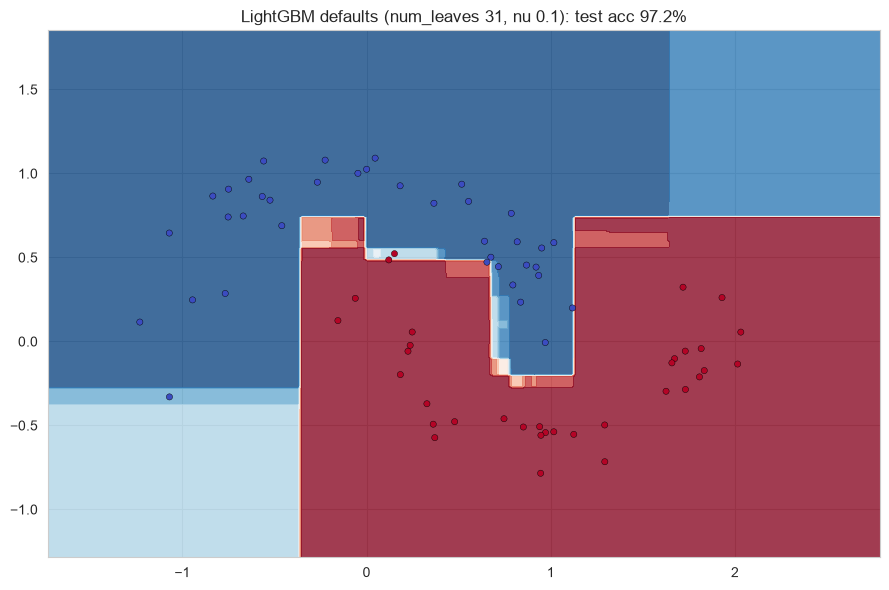


💡 Same lesson as notebook 09's XGBoost defaults, from the other direction:
   num_leaves = 31 is a large-data design - on 168 rows the min_child_samples
   gate quietly holds it down (trees_to_dataframe shows the ACTUAL leaf count).
   Small-data runs should move num_leaves, not fight the gate by surprise.


In [12]:
# First fit: the estimator interface at LightGBM's own defaults
Xm6, ym6 = make_moons(n_samples=240, noise=0.15, random_state=0)
Xm6_tr, Xm6_te, ym6_tr, ym6_te = train_test_split(Xm6, ym6, test_size=0.3, random_state=42)

clf_lgb_first = LGBMClassifier(random_state=0).fit(Xm6_tr, ym6_tr)
defaults_lgb = clf_lgb_first.get_params()
show_lgb = ["num_leaves", "max_depth", "learning_rate", "n_estimators",
            "min_child_samples", "min_child_weight", "min_split_gain",
            "subsample", "subsample_freq", "colsample_bytree",
            "reg_alpha", "reg_lambda", "importance_type", "n_jobs"]
print("LightGBM defaults the wrapper resolves (a few, verified from get_params()):")
for key_lgb in show_lgb:
    print(f"  {key_lgb:>18s} = {defaults_lgb[key_lgb]!r}")

proba_first_lgb = clf_lgb_first.predict_proba(Xm6_te)
tdf_first = clf_lgb_first.booster_.trees_to_dataframe()
tree0_first = tdf_first[tdf_first["tree_index"] == 0]
rows_leaf_first = len(Xm6_tr)
print(f"\ntrees in the ensemble:  {clf_lgb_first.booster_.num_trees()}")
print(f"tree 0: actual leaves {int(tree0_first['split_feature'].isna().sum())} "
      f"(requested num_leaves = 31)")
print(f"  - with n_train = {rows_leaf_first} rows and min_child_samples = 20, the row gate")
print(f"    caps any tree near floor({rows_leaf_first} / 20) = {rows_leaf_first // 20} leaves")
print(f"test accuracy {clf_lgb_first.score(Xm6_te, ym6_te):.1%} | "
      f"proba rows sum to 1: {np.allclose(proba_first_lgb.sum(axis=1), 1)}")

pad_first_lgb = 0.5
xx_first_lgb, yy_first_lgb = np.meshgrid(
    np.linspace(Xm6[:, 0].min() - pad_first_lgb, Xm6[:, 0].max() + pad_first_lgb, 220),
    np.linspace(Xm6[:, 1].min() - pad_first_lgb, Xm6[:, 1].max() + pad_first_lgb, 220),
)
grid_first_lgb = np.c_[xx_first_lgb.ravel(), yy_first_lgb.ravel()]
field_first_lgb = clf_lgb_first.predict_proba(grid_first_lgb)[:, 1].reshape(xx_first_lgb.shape)

fig, ax_first_lgb = plt.subplots(figsize=(9, 6))
ax_first_lgb.contourf(xx_first_lgb, yy_first_lgb, field_first_lgb,
                      levels=np.linspace(0.0, 1.0, 11), cmap="RdBu_r", alpha=0.8)
ax_first_lgb.scatter(Xm6_te[:, 0], Xm6_te[:, 1], c=ym6_te, cmap="coolwarm", s=20,
                     edgecolors="k", linewidths=0.3)
ax_first_lgb.set_title("LightGBM defaults (num_leaves 31, nu 0.1): "
                       f"test acc {clf_lgb_first.score(Xm6_te, ym6_te):.1%}")
plt.tight_layout()
plt.show()

print("\n💡 Same lesson as notebook 09's XGBoost defaults, from the other direction:")
print("   num_leaves = 31 is a large-data design - on 168 rows the min_child_samples")
print("   gate quietly holds it down (trees_to_dataframe shows the ACTUAL leaf count).")
print("   Small-data runs should move num_leaves, not fight the gate by surprise.")

### Dual Engine: the Family Twin vs LightGBM on the Same Data

Both engines get the identical moons split, 40 stages, $\nu = 0.1$. To make the comparison sharp, the parity knobs are aligned with the binary twin: `num_leaves = 8` on both sides (the twin's depth-3 stage tree can hold at most 8 leaves), `min_child_samples = 1` and `min_child_weight = 1e-12` leave the gate defaults out of the picture, and sampling/λ stay at their inert defaults on LightGBM's side. A third LightGBM run turns on GOSS — same engine, sampled rows.

Expect close but not identical, for the same reasons notebook 08/09 listed, reshaped:

- **Split criterion**: the twin fits each stage's regression tree on residuals by least squares; LightGBM prices every candidate on the λ-smoothed gain (§5's grower did the same and still produced different trees)
- **Histogram candidates**: LightGBM proposes cuts from up to 255 bins (`max_bin`), the twin scans raw feature values — different candidate grids where the data is dense
- **The leaf-wise budget**: at `num_leaves = 8` both engines land near balanced trees, but LightGBM is guaranteed to spend all 8 leaves while the twin's least-squares tree may stop early on pure clusters
- **GOSS rows**: the third run changes the data the stages see, so its curve moves for sampling reasons, not objective ones

                                 twin        lgb   lgb goss
test accuracy                   95.8%      98.6%      98.6%
mean |p - p_twin|                         0.0653     0.0630
label agreement                            97.2%      97.2%
fit time (s)                                0.01       0.01 (1.12 for the twin)


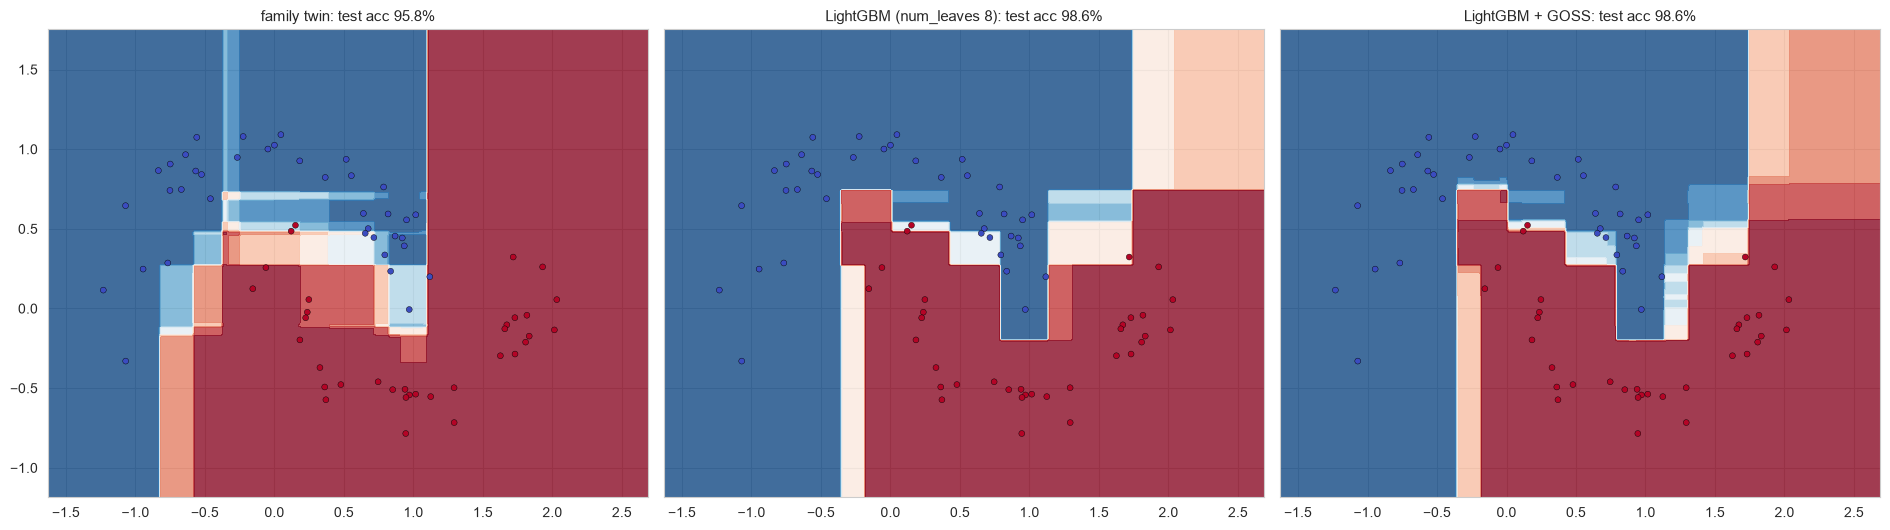


💡 Same skeleton, same leaf math, different split currency and tree shape -> the
   three fields agree in structure and differ in texture. The GOSS field shows
   sampling noise exactly where the gradient mass was small - GOSS's honest toll.


In [13]:
PAR_LGB = dict(n_estimators=40, learning_rate=NU_HAND, num_leaves=8,
               min_child_samples=1, min_child_weight=1e-12, verbosity=-1)

t0 = time.perf_counter()
twin_de = GradientBoostingClassifierScratch(n_estimators=40, learning_rate=NU_HAND,
                                            max_depth=3).fit(Xm6_tr, ym6_tr)
t_twin_de = time.perf_counter() - t0

t0 = time.perf_counter()
lgb_de = LGBMClassifier(random_state=0, **PAR_LGB).fit(Xm6_tr, ym6_tr)
t_lgb_de = time.perf_counter() - t0

t0 = time.perf_counter()
lgb_de_goss = LGBMClassifier(data_sample_strategy="goss", top_rate=0.2, other_rate=0.1,
                             random_state=0, **PAR_LGB).fit(Xm6_tr, ym6_tr)
t_lgb_goss_de = time.perf_counter() - t0

proba_twin_de = twin_de.predict_proba(Xm6_te)[:, 1]
proba_lgb_de = lgb_de.predict_proba(Xm6_te)[:, 1]
proba_goss_de = lgb_de_goss.predict_proba(Xm6_te)[:, 1]

print(f"{'':26s} {'twin':>10s} {'lgb':>10s} {'lgb goss':>10s}")
print(f"{'test accuracy':26s} {twin_de.score(Xm6_te, ym6_te):>10.1%} "
      f"{lgb_de.score(Xm6_te, ym6_te):>10.1%} {lgb_de_goss.score(Xm6_te, ym6_te):>10.1%}")
print(f"{'mean |p - p_twin|':26s} {'':>10s} "
      f"{np.abs(proba_lgb_de - proba_twin_de).mean():>10.4f} "
      f"{np.abs(proba_goss_de - proba_twin_de).mean():>10.4f}")
print(f"{'label agreement':26s} {'':>10s} "
      f"{np.mean((proba_lgb_de >= 0.5) == (proba_twin_de >= 0.5)):>10.1%} "
      f"{np.mean((proba_goss_de >= 0.5) == (proba_twin_de >= 0.5)):>10.1%}")
print(f"{'fit time (s)':26s} {'':>10s} {t_lgb_de:>10.2f} {t_lgb_goss_de:>10.2f} "
      f"({t_twin_de:.2f} for the twin)")

pad_de_lgb = 0.4
xx_de_lgb, yy_de_lgb = np.meshgrid(
    np.linspace(Xm6[:, 0].min() - pad_de_lgb, Xm6[:, 0].max() + pad_de_lgb, 250),
    np.linspace(Xm6[:, 1].min() - pad_de_lgb, Xm6[:, 1].max() + pad_de_lgb, 250),
)
grid_de_lgb = np.c_[xx_de_lgb.ravel(), yy_de_lgb.ravel()]
fig, axes_de_lgb = plt.subplots(1, 3, figsize=(19, 5.4), sharey=True)
for ax_de, (name_de, est_de) in zip(axes_de_lgb, [("family twin", twin_de),
                                                  ("LightGBM (num_leaves 8)", lgb_de),
                                                  ("LightGBM + GOSS", lgb_de_goss)]):
    Z_de = est_de.predict_proba(grid_de_lgb)[:, 1].reshape(xx_de_lgb.shape)
    ax_de.contourf(xx_de_lgb, yy_de_lgb, Z_de, levels=np.linspace(0.0, 1.0, 11),
                   cmap="RdBu_r", alpha=0.8)
    ax_de.scatter(Xm6_te[:, 0], Xm6_te[:, 1], c=ym6_te, cmap="coolwarm", s=18,
                  edgecolors="k", linewidths=0.3)
    ax_de.set_title(f"{name_de}: test acc {est_de.score(Xm6_te, ym6_te):.1%}", fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Same skeleton, same leaf math, different split currency and tree shape -> the")
print("   three fields agree in structure and differ in texture. The GOSS field shows")
print("   sampling noise exactly where the gradient mass was small - GOSS's honest toll.")

### Regression with LightGBM: `LGBMRegressor`

The same staged machinery under the squared-error objective. In the shipped objective source the first-order term is $g = F - y$ (score minus label — the same bookkeeping sign notebook 09 used for XGBoost) with constant curvature $h = 1$, so every leaf value is the (λ-smoothed) **mean residual** of its leaf, and the gain is its MSE-flavored twin.

Depth-to-budget translation: "stumps" in LightGBM is `num_leaves = 2` — one split per stage, the bias-heavy low-variance point of the sweep.

*(The family twin is classifier-first — the squared-error leaf math is §5's grower with $h \equiv 1$; multiclass and regression stay library-side here.)*

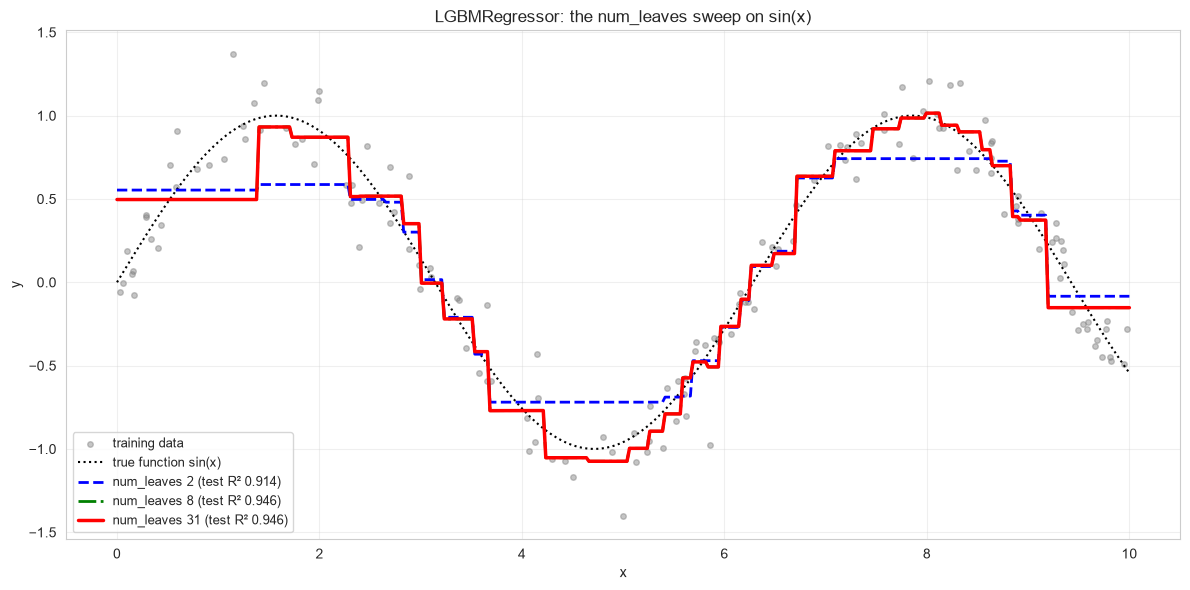

num_leaves=2: train R² 0.8328 | test R² 0.9138 | test RMSE 0.2088
num_leaves=8: train R² 0.8812 | test R² 0.9460 | test RMSE 0.1652
num_leaves=31: train R² 0.8812 | test R² 0.9460 | test RMSE 0.1652

💡 num_leaves = 2 is LightGBM's stump: one split per stage, smooth steps, extra
   stages needed. num_leaves = 8 nails the shape; 31 spends its budget inside a
   200-row training window - the same small-data wobble the trees picked out in
   notebooks 03/04, one budget-width deeper.


In [14]:
rng_r_lgb = np.random.default_rng(0)
X_r10 = np.sort(rng_r_lgb.uniform(0.0, 10.0, 200)).reshape(-1, 1)
y_r10 = np.sin(X_r10).ravel() + rng_r_lgb.normal(0.0, 0.15, 200)
Xr10_tr, Xr10_te, yr10_tr, yr10_te = train_test_split(X_r10, y_r10, test_size=0.25,
                                                      random_state=42)

reg_lgb_d2 = LGBMRegressor(num_leaves=2, n_estimators=200, learning_rate=0.1,
                           verbosity=-1, random_state=0).fit(Xr10_tr, yr10_tr)
reg_lgb_d8 = LGBMRegressor(num_leaves=8, n_estimators=200, learning_rate=0.1,
                           verbosity=-1, random_state=0).fit(Xr10_tr, yr10_tr)
reg_lgb_d31 = LGBMRegressor(n_estimators=200, learning_rate=0.1, verbosity=-1,
                            random_state=0).fit(Xr10_tr, yr10_tr)

grid_r_lgb = np.linspace(0.0, 10.0, 400).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(Xr10_tr[:, 0], yr10_tr, s=16, alpha=0.45, color="gray", label="training data")
ax.plot(grid_r_lgb, np.sin(grid_r_lgb), "k:", lw=1.5, label="true function sin(x)")
ax.plot(grid_r_lgb, reg_lgb_d2.predict(grid_r_lgb), "b--", lw=2,
        label=f"num_leaves 2 (test R² {r2_score(yr10_te, reg_lgb_d2.predict(Xr10_te)):.3f})")
ax.plot(grid_r_lgb, reg_lgb_d8.predict(grid_r_lgb), "g-.", lw=2,
        label=f"num_leaves 8 (test R² {r2_score(yr10_te, reg_lgb_d8.predict(Xr10_te)):.3f})")
ax.plot(grid_r_lgb, reg_lgb_d31.predict(grid_r_lgb), "r-", lw=2.5,
        label=f"num_leaves 31 (test R² {r2_score(yr10_te, reg_lgb_d31.predict(Xr10_te)):.3f})")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("LGBMRegressor: the num_leaves sweep on sin(x)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name_reg, reg_r in [("num_leaves=2", reg_lgb_d2), ("num_leaves=8", reg_lgb_d8),
                        ("num_leaves=31", reg_lgb_d31)]:
    print(f"{name_reg}: train R² {reg_r.score(Xr10_tr, yr10_tr):.4f} | "
          f"test R² {r2_score(yr10_te, reg_r.predict(Xr10_te)):.4f} | "
          f"test RMSE {np.sqrt(mean_squared_error(yr10_te, reg_r.predict(Xr10_te))):.4f}")
print("\n💡 num_leaves = 2 is LightGBM's stump: one split per stage, smooth steps, extra")
print("   stages needed. num_leaves = 8 nails the shape; 31 spends its budget inside a")
print("   200-row training window - the same small-data wobble the trees picked out in")
print("   notebooks 03/04, one budget-width deeper.")

### The Native API: `lgb.Dataset` and `lgb.train`

The estimator interface is the tool for notebook-style work; the native API is what production LightGBM is written against:

- **`lgb.Dataset`**: LightGBM's internal container — quantizes features into up to `max_bin` bins ONCE, caches them for every round, carries weights/groups/feature names. Construct once, train repeatedly.
- **`lgb.train(params, train_set, num_boost_round=..., valid_sets=..., callbacks=...)`**: the native loop. Early stopping is a callback (`lgb.early_stopping(stopping_rounds=k, first_metric_only=...)`); the [LightGBM] log chatter is silenced with `lgb.log_evaluation(period=0)`
- **Eval history is a callback too**: `lgb.record_evaluation(history_dict)` fills a dict you own with `{"training": {...}, "valid_1": {...}}` — the native `Booster` has **no** `evals_result()` method (that is XGBoost's API); the sklearn wrapper renders the same machinery as its `evals_result_` property
- **`Booster` reads**: `best_iteration`, `feature_importance(importance_type=...)`, `predict(..., pred_contrib=True)` (SHAP-style contributions), `trees_to_dataframe()`, `save_model(...)` — the encoding stays text-JSON stable
- `valid_sets` order defines the `record_evaluation` keys; label constraints belong to the native objective (binary wants {0, 1})

The demo below repeats the wrapper's mood on the moons data — `lgb.train` with a validation watch list and the early-stopping callback.

In [15]:
dtrain_native = lgb.Dataset(Xm6_tr, label=ym6_tr)
dvalid_native = lgb.Dataset(Xm6_te, label=ym6_te, reference=dtrain_native)

params_native = {
    "objective": "binary",
    "metric": ["binary_logloss", "auc"],
    "learning_rate": NU_HAND,
    "num_leaves": 8,
    "min_child_samples": 1,
    "min_child_weight": 1e-12,
}
# The native recorder: lgb.record_evaluation fills a dict you own - the Booster
# object itself carries no evals_result() (that is XGBoost's Booster method)
evals_native = {}
t0 = time.perf_counter()
booster_native = lgb.train(
    params_native,
    train_set=dtrain_native,
    num_boost_round=300,
    valid_sets=[dtrain_native, dvalid_native],
    callbacks=[lgb.record_evaluation(evals_native),
               lgb.early_stopping(stopping_rounds=15, verbose=False),
               lgb.log_evaluation(period=0)],
)
t_native = time.perf_counter() - t0

h_native = evals_native
best_key_native = "valid_1"          # valid_sets order: [training, valid_1]
print(f"record_evaluation dict keys: {list(h_native)}")
print(f"stopped with best_iteration = {booster_native.best_iteration} of 300 requested rounds")
print(f"native API test accuracy: "
      f"{accuracy_score(ym6_te, (booster_native.predict(Xm6_te) >= 0.5).astype(int)):.1%}"
      f"  (Booster.predict uses the best iteration automatically, same as the wrapper)")
print(f"metrics recorded: {list(h_native[best_key_native])}")
print(f"validation logloss at the best round: "
      f"{min(h_native[best_key_native]['binary_logloss']):.4f}")
print(f"round budget spent {t_native:.2f} s")

# Native SHAP-style contributions - one predict call, no extra package
contribs_native = booster_native.predict(Xm6_te, pred_contrib=True)
print(f"\npred_contrib matrix: {contribs_native.shape}  (last column is the bias term)")
i_row = int(np.argmax(np.abs(contribs_native[:, :-1]).sum(axis=1)))
print(f"most-influenced test row #{i_row}: dominant feature index "
      f"{int(np.argmax(np.abs(contribs_native[i_row, :-1])))}, "
      f"bias {contribs_native[i_row, -1]:+.3f}")

print("\n💡 The native door is the same engine with the switches exposed: bins created")
print("   once on the Dataset, early stopping as a callback, contributions from")
print("   predict(...) - and 4.x's best-iteration rule clears notebook 09's native-predict")
print("   trap for good.")

record_evaluation dict keys: ['training', 'valid_1']
stopped with best_iteration = 6 of 300 requested rounds
native API test accuracy: 95.8%  (Booster.predict uses the best iteration automatically, same as the wrapper)
metrics recorded: ['binary_logloss', 'auc']
validation logloss at the best round: 0.1165
round budget spent 0.02 s

pred_contrib matrix: (72, 3)  (last column is the bias term)
most-influenced test row #46: dominant feature index 0, bias +0.059

💡 The native door is the same engine with the switches exposed: bins created
   once on the Dataset, early stopping as a callback, contributions from
   predict(...) - and 4.x's best-iteration rule clears notebook 09's native-predict
   trap for good.


lgb_de.feature_importances_ == its own Booster.feature_importance('split'): True
native default importance_type = 'split' (XGBoost's wrapper defaults to 'gain'); 'total_gain'/'total_split' join the menu since 4.0


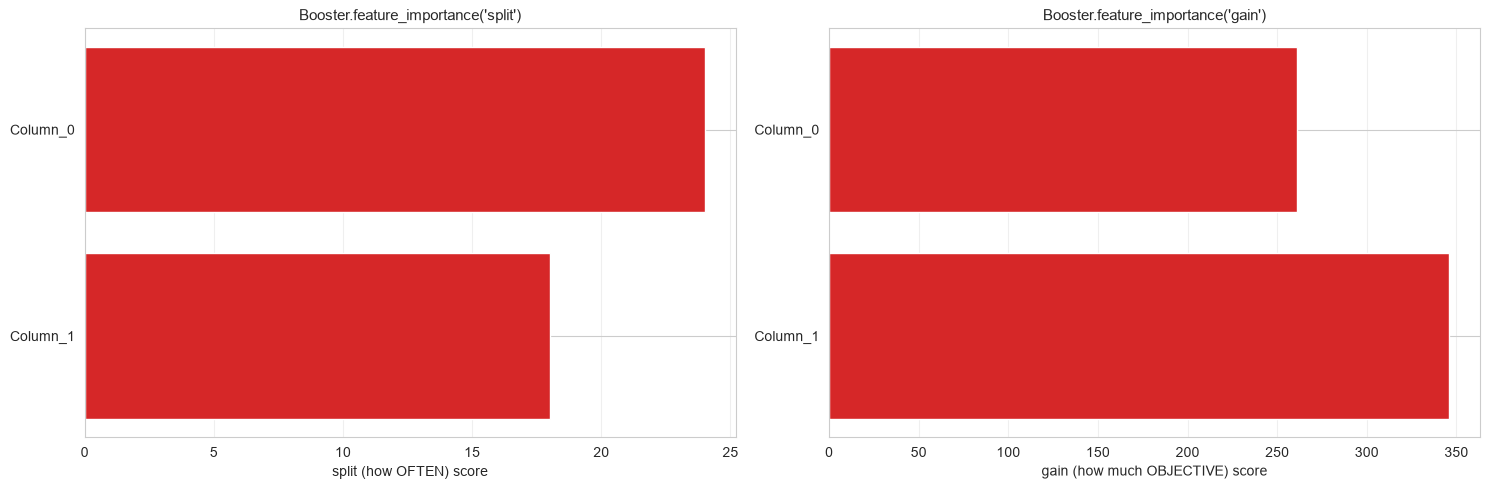

top by split count: ['Column_0', 'Column_1']   |   top by gain: ['Column_1', 'Column_0']

💡 'split' counts usage, 'gain' counts objective repair (§2's G²/(H+lambda) sums).
   A workhorse feature can dominate the split column on noise-free ties where a
   high-gain feature only fires three times - read both before acting, exactly the
   notebook 04/09 advice, one engine later.


In [16]:
# Which importance is which: split vs gain, native booster and its own wrapper read
importance_native_split = pd.Series(
    booster_native.feature_importance(importance_type="split"),
    index=booster_native.feature_name())
importance_native_gain = pd.Series(
    booster_native.feature_importance(importance_type="gain"),
    index=booster_native.feature_name())

# the wrapper attribute and its own booster's native call agree by forwarding
wrapper_vs_native = np.allclose(lgb_de.feature_importances_,
                                lgb_de.booster_.feature_importance(importance_type="split"))
print(f"lgb_de.feature_importances_ == its own Booster.feature_importance('split'): "
      f"{wrapper_vs_native}")
print("native default importance_type = 'split' (XGBoost's wrapper defaults to 'gain');"
      " 'total_gain'/'total_split' join the menu since 4.0")

fig, axes_imp = plt.subplots(1, 2, figsize=(15, 5))
for ax_imp, (imp_name, imp_vals) in zip(axes_imp, [("split (how OFTEN)", importance_native_split),
                                                    ("gain (how much OBJECTIVE)", importance_native_gain)]):
    ax_imp.barh(imp_vals.index[::-1], imp_vals.values[::-1], color="#d62728")
    ax_imp.set_xlabel(f"{imp_name} score")
    ax_imp.set_title(f"Booster.feature_importance('{imp_name.split(' ')[0]}')",
                     fontsize=11)
    ax_imp.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

top_split = importance_native_split.sort_values(ascending=False).head(2)
top_gain = importance_native_gain.sort_values(ascending=False).head(2)
print(f"top by split count: {list(top_split.index)}   |   top by gain: {list(top_gain.index)}")
print("\n💡 'split' counts usage, 'gain' counts objective repair (§2's G²/(H+lambda) sums).")
print("   A workhorse feature can dominate the split column on noise-free ties where a")
print("   high-gain feature only fires three times - read both before acting, exactly the")
print("   notebook 04/09 advice, one engine later.")

---

## 7. Hyperparameter Tuning

The levers that matter, in the order they are usually tuned:

1. **`num_leaves`** (+ `max_depth` as the safety cap) — THE shape budget; leaf-wise growth spends it greedily
2. **`min_child_samples` / `min_child_weight`** — the leaf floors that keep greedy growth honest
3. **`learning_rate` × `n_estimators`** (native aliases `eta` / `num_iterations`) — one trade: small η needs many stages, big η can be wrong outright
4. **`subsample` + `subsample_freq` / `colsample_bytree`** — the stochastic dampers; bagging needs its frequency key
5. **`reg_lambda` / `reg_alpha`** — the regularizers, both OFF by default in LightGBM

Four rules govern the sweeps:

1. η, λ, α act multiplicatively — log-scale grids, never linear
2. **η and stage count move together**; tune one, re-check the other
3. Tune with **cross-validation on training data only**; the test set reports once
4. `n_jobs`: LightGBM defaults to **all cores** (`num_threads = 0`); set LightGBM's `n_jobs=1` inside a parallel sklearn sweep (`GridSearchCV(n_jobs=-1)`) to avoid thread thrashing — same advice as XGBoost, same reason

The tuning data below is a noisier moons set (480 rows, noise 0.25) — the same recipe as notebooks 08/09, so the hyperparameter stories compare stage for stage.

In [17]:
# The tuning split used throughout section 7
Xt7, yt7 = make_moons(n_samples=480, noise=0.25, random_state=3)
Xt7_tr, Xt7_te, yt7_tr, yt7_te = train_test_split(Xt7, yt7, test_size=0.3,
                                                  stratify=yt7, random_state=42)
print(f"tuning data: {Xt7_tr.shape[0]} train rows / {Xt7_te.shape[0]} test rows, noise 0.25")

tuning data: 336 train rows / 144 test rows, noise 0.25


 num_leaves  train acc  test acc
          2     0.9524    0.8819
          4     1.0000    0.8819
          8     1.0000    0.8681
         16     1.0000    0.8750
         32     1.0000    0.8750
         64     1.0000    0.8958


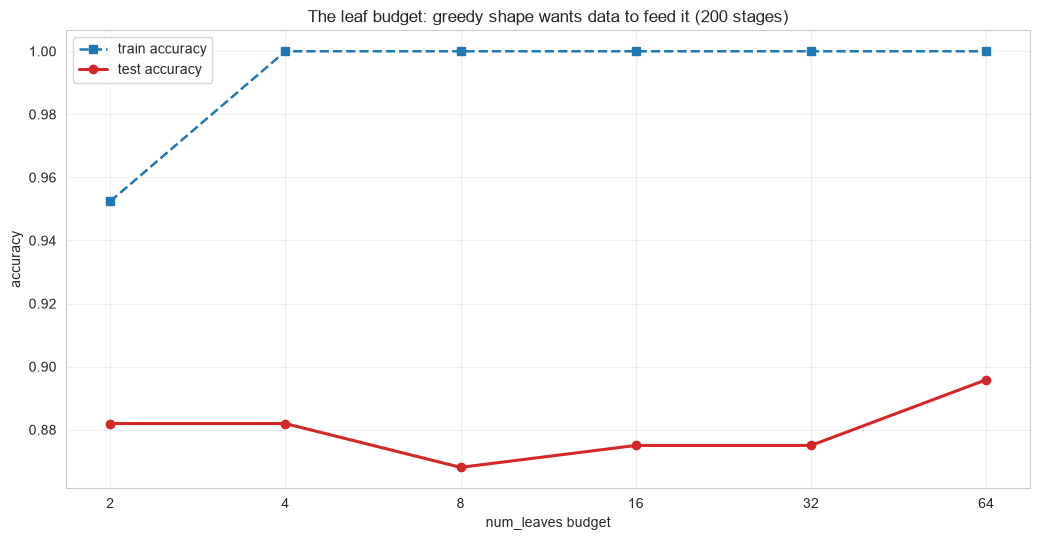


💡 Same shape as section 5's sweep, now on the compiled engine: each extra leaf
   must EARN its rows. By num_leaves = 64 the extra depth lands on residual noise -
   train climbs toward 1.0 while test wobbles - the signal to pair a bigger budget
   with a bigger leaf floor or more rows.


In [18]:
# The num_leaves sweep: 200 stages at nu = 0.1; min_child_samples = 1 so the budget is honest
lgb_leaves_sweep = [2, 4, 8, 16, 32, 64]
rows_leaves = []
for T_lgb in lgb_leaves_sweep:
    m_lgb = LGBMClassifier(num_leaves=T_lgb, n_estimators=200, learning_rate=0.1,
                           min_child_samples=1, verbosity=-1, random_state=0)
    m_lgb.fit(Xt7_tr, yt7_tr)
    rows_leaves.append({"num_leaves": T_lgb,
                        "train acc": m_lgb.score(Xt7_tr, yt7_tr),
                        "test acc": m_lgb.score(Xt7_te, yt7_te)})

df_leaves = pd.DataFrame(rows_leaves)
print(df_leaves.round(4).to_string(index=False))

fig, ax_leaves = plt.subplots(figsize=(10.5, 5.5))
ax_leaves.plot(df_leaves["num_leaves"], df_leaves["train acc"], "s--", color="#1f77b4",
               lw=1.8, label="train accuracy")
ax_leaves.plot(df_leaves["num_leaves"], df_leaves["test acc"], "o-", color="#d62728",
               lw=2.2, label="test accuracy")
ax_leaves.set_xscale("log", base=2)
ax_leaves.set_xticks(lgb_leaves_sweep, [str(T_lgb) for T_lgb in lgb_leaves_sweep])
ax_leaves.set_xlabel("num_leaves budget")
ax_leaves.set_ylabel("accuracy")
ax_leaves.set_title("The leaf budget: greedy shape wants data to feed it (200 stages)")
ax_leaves.legend()
ax_leaves.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Same shape as section 5's sweep, now on the compiled engine: each extra leaf")
print("   must EARN its rows. By num_leaves = 64 the extra depth lands on residual noise -")
print("   train climbs toward 1.0 while test wobbles - the signal to pair a bigger budget")
print("   with a bigger leaf floor or more rows.")

### The Leaf Floors: `min_child_samples` and `min_child_weight`

The floors are what keep the greedy frontier honest: a candidate split whose children can't carry enough **rows** (`min_child_samples`, default 20) or enough **hessian mass** (`min_child_weight`, default 1e-3) never happens. Notebook 09's `min_child_weight` story is here in full — plus the row-count floor the depth-wise engines express through notebook 03's `min_samples_leaf`.

Under log-loss a row's hessian is at most $0.25$ (rows start near $h \approx 0.25$, and near-certain rows decay toward 0), so the hessian floor binds late; the row floor binds first. Two sweeps:

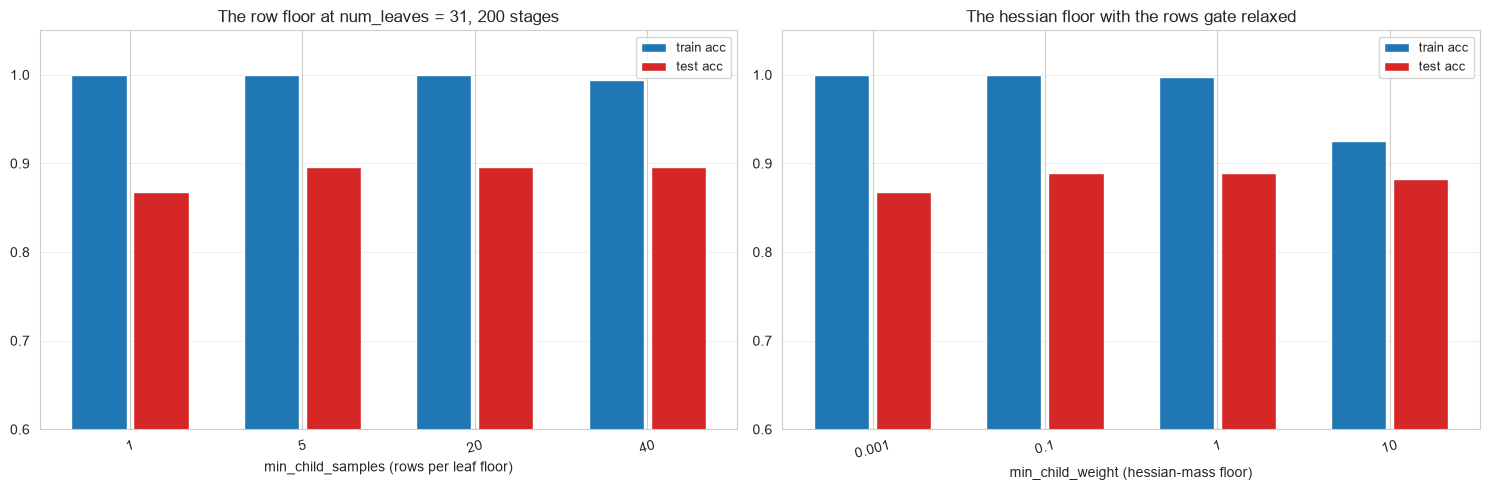

 min_child_samples  train acc  test acc
                 1     1.0000    0.8681
                 5     1.0000    0.8958
                20     1.0000    0.8958
                40     0.9940    0.8958

 min_child_weight  train acc  test acc
           0.0010     1.0000    0.8681
           0.1000     1.0000    0.8889
           1.0000     0.9970    0.8889
          10.0000     0.9256    0.8819

💡 Raising min_child_samples prunes the periphery first - the exact mirror of
   notebook 03's min_samples_leaf and notebook 09's min_child_weight, now in
   row units. The hessian floor moves late (rows carry at most 0.25 of h each);
   it is the finer instrument, meaningful once plenty of data flows in.


In [19]:
mcs_sweep = [1, 5, 20, 40]
rows_mcs = []
for mcs_lgb in mcs_sweep:
    m_lgb = LGBMClassifier(num_leaves=31, n_estimators=200, learning_rate=0.1,
                           min_child_samples=mcs_lgb, verbosity=-1, random_state=0)
    m_lgb.fit(Xt7_tr, yt7_tr)
    rows_mcs.append({"min_child_samples": mcs_lgb,
                     "train acc": m_lgb.score(Xt7_tr, yt7_tr),
                     "test acc": m_lgb.score(Xt7_te, yt7_te)})

mcw_sweep = [0.001, 0.1, 1.0, 10.0]
rows_mcw = []
for mcw_lgb in mcw_sweep:
    m_lgb = LGBMClassifier(num_leaves=31, n_estimators=200, learning_rate=0.1,
                           min_child_samples=1, min_child_weight=mcw_lgb,
                           verbosity=-1, random_state=0)
    m_lgb.fit(Xt7_tr, yt7_tr)
    rows_mcw.append({"min_child_weight": mcw_lgb,
                     "train acc": m_lgb.score(Xt7_tr, yt7_tr),
                     "test acc": m_lgb.score(Xt7_te, yt7_te)})

df_mcs = pd.DataFrame(rows_mcs)
df_mcw = pd.DataFrame(rows_mcw)

fig, axes_floors = plt.subplots(1, 2, figsize=(15, 5))
x_pos_mcs = np.arange(len(df_mcs))
axes_floors[0].bar(x_pos_mcs - 0.18, df_mcs["train acc"], width=0.32, color="#1f77b4",
                   label="train acc")
axes_floors[0].bar(x_pos_mcs + 0.18, df_mcs["test acc"], width=0.32, color="#d62728",
                   label="test acc")
axes_floors[0].set_xticks(x_pos_mcs, df_mcs["min_child_samples"].astype(str),
                          rotation=15)
axes_floors[0].set_ylim(0.6, 1.05)
axes_floors[0].set_xlabel("min_child_samples (rows per leaf floor)")
axes_floors[0].legend(fontsize=9)
axes_floors[0].grid(True, axis="y", alpha=0.3)
axes_floors[0].set_title("The row floor at num_leaves = 31, 200 stages")

x_pos_mcw = np.arange(len(df_mcw))
axes_floors[1].bar(x_pos_mcw - 0.18, df_mcw["train acc"], width=0.32, color="#1f77b4",
                   label="train acc")
axes_floors[1].bar(x_pos_mcw + 0.18, df_mcw["test acc"], width=0.32, color="#d62728",
                   label="test acc")
axes_floors[1].set_xticks(x_pos_mcw, [f"{v_lgb:g}" for v_lgb in df_mcw["min_child_weight"]],
                          rotation=15)
axes_floors[1].set_ylim(0.6, 1.05)
axes_floors[1].set_xlabel("min_child_weight (hessian-mass floor)")
axes_floors[1].legend(fontsize=9)
axes_floors[1].grid(True, axis="y", alpha=0.3)
axes_floors[1].set_title("The hessian floor with the rows gate relaxed")
plt.tight_layout()
plt.show()

print(df_mcs.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print(df_mcw.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\n💡 Raising min_child_samples prunes the periphery first - the exact mirror of")
print("   notebook 03's min_samples_leaf and notebook 09's min_child_weight, now in")
print("   row units. The hessian floor moves late (rows carry at most 0.25 of h each);")
print("   it is the finer instrument, meaningful once plenty of data flows in.")

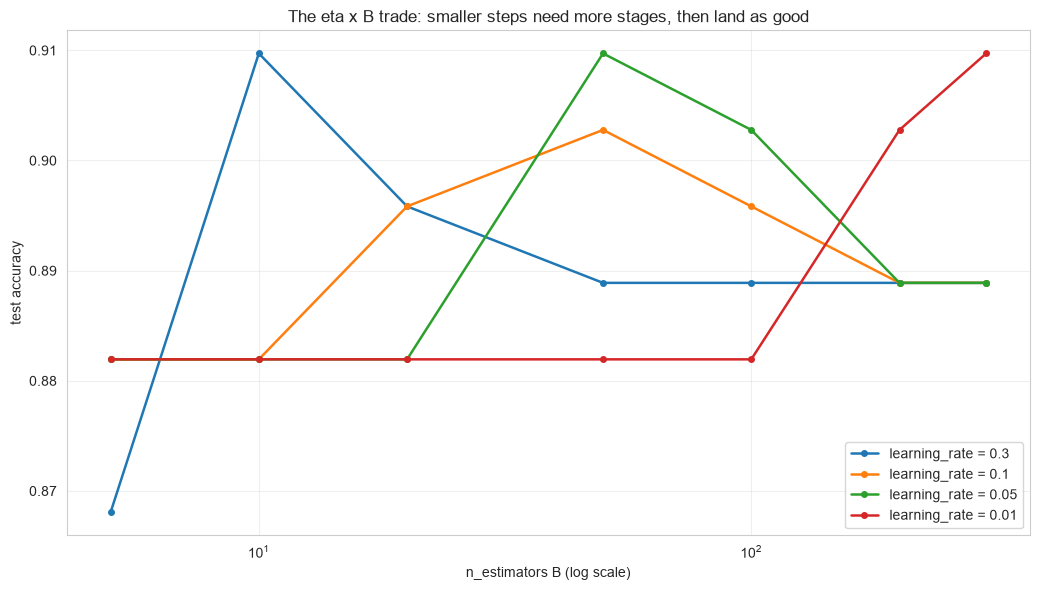

   eta | best B | best test acc
  0.30 |     10 |         91.0%
  0.10 |     50 |         90.3%
  0.05 |     50 |         91.0%
  0.01 |    300 |         91.0%

💡 Notebook 08/09's trade, unchanged by the growth policy: eta = 0.3 peaks early
   and wobbles; eta = 0.01 keeps climbing through 300 stages. Pick eta by the stage
   budget you can afford, add early stopping, and let the validation curve pick B.


In [20]:
# The eta x n_estimators trade: refits across a stage grid (no staged predictor in a compiled engine)
B_lgb_sweep = [5, 10, 20, 50, 100, 200, 300]
eta_lgb_sweep = [0.3, 0.1, 0.05, 0.01]
acc_by_eta_lgb = {}
for eta_lgb in eta_lgb_sweep:
    test_curve_lgb = []
    for B_lgb in B_lgb_sweep:
        m_lgb = LGBMClassifier(num_leaves=16, n_estimators=B_lgb, learning_rate=eta_lgb,
                               verbosity=-1, random_state=0)
        test_curve_lgb.append(accuracy_score(yt7_te, m_lgb.fit(Xt7_tr, yt7_tr).predict(Xt7_te)))
    acc_by_eta_lgb[eta_lgb] = np.array(test_curve_lgb)

fig, ax_eta = plt.subplots(figsize=(10.5, 6))
for eta_lgb in eta_lgb_sweep:
    ax_eta.plot(B_lgb_sweep, acc_by_eta_lgb[eta_lgb], marker="o", ms=4, lw=1.8,
                label=f"learning_rate = {eta_lgb}")
ax_eta.set_xscale("log")
ax_eta.set_xlabel("n_estimators B (log scale)")
ax_eta.set_ylabel("test accuracy")
ax_eta.set_title("The eta x B trade: smaller steps need more stages, then land as good")
ax_eta.legend()
ax_eta.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'eta':>6s} | {'best B':>6s} | {'best test acc':>13s}")
for eta_lgb in eta_lgb_sweep:
    best_i_lgb = int(acc_by_eta_lgb[eta_lgb].argmax())
    print(f"{eta_lgb:>6.2f} | {B_lgb_sweep[best_i_lgb]:>6d} | "
          f"{acc_by_eta_lgb[eta_lgb][best_i_lgb]:>13.1%}")
print("\n💡 Notebook 08/09's trade, unchanged by the growth policy: eta = 0.3 peaks early")
print("   and wobbles; eta = 0.01 keeps climbing through 300 stages. Pick eta by the stage")
print("   budget you can afford, add early stopping, and let the validation curve pick B.")

In [21]:
# subsample x colsample_bytree under 3-fold stratified CV
# (subsample_freq = 1 is what turns bagging ON - LightGBM's frequency key)
grid_sub_lgb = GridSearchCV(
    LGBMClassifier(num_leaves=16, n_estimators=150, learning_rate=0.1,
                   subsample_freq=1, n_jobs=1, verbosity=-1, random_state=0),
    {"subsample": [1.0, 0.8, 0.6], "colsample_bytree": [1.0, 0.7, 0.5]},
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    n_jobs=-1,
)
grid_sub_lgb.fit(Xt7_tr, yt7_tr)

pivot_sub_lgb = pd.DataFrame(grid_sub_lgb.cv_results_).pivot_table(
    values="mean_test_score", index="param_subsample", columns="param_colsample_bytree")
print(pivot_sub_lgb.round(4).to_string())
print(f"\nbest: {grid_sub_lgb.best_params_}  "
      f"(CV acc {grid_sub_lgb.best_score_:.4f}; "
      f"test acc {grid_sub_lgb.score(Xt7_te, yt7_te):.4f})")

# The migration gotcha, isolated: the SAME subsample with the default subsample_freq = 0
m_active = LGBMClassifier(num_leaves=16, n_estimators=150, learning_rate=0.1,
                          subsample=0.6, subsample_freq=1, n_jobs=1, verbosity=-1,
                          random_state=0)
m_inert = LGBMClassifier(num_leaves=16, n_estimators=150, learning_rate=0.1,
                         subsample=0.6, n_jobs=1, verbosity=-1, random_state=0)
cv_gotcha = StratifiedKFold(3, shuffle=True, random_state=42)
acc_active = cross_val_score(m_active, Xt7_tr, yt7_tr, cv=cv_gotcha,
                             scoring="accuracy", n_jobs=-1).mean()
acc_inert = cross_val_score(m_inert, Xt7_tr, yt7_tr, cv=cv_gotcha,
                            scoring="accuracy", n_jobs=-1).mean()
print(f"\nsubsample = 0.6 WITH subsample_freq = 1:    CV acc {acc_active:.4f}")
print(f"subsample = 0.6 with DEFAULT subsample_freq (0): CV acc {acc_inert:.4f}")
print("(the second one bagged NOTHING - the same rows every fold, full batch)")
print("\n💡 Row bagging is TWO keys in LightGBM: fraction AND frequency. Porting an XGBoost")
print("   config with subsample = 0.8 alone silently trains full-batch - the config read")
print("   fine and did less than it said. Column sampling (colsample_bytree) has no such")
print("   second key.")

param_colsample_bytree     0.5     0.7     1.0
param_subsample                               
0.6                     0.9196  0.9196  0.9226
0.8                     0.9226  0.9226  0.9196
1.0                     0.9256  0.9256  0.9226

best: {'colsample_bytree': 0.7, 'subsample': 1.0}  (CV acc 0.9256; test acc 0.8750)

subsample = 0.6 WITH subsample_freq = 1:    CV acc 0.9226
subsample = 0.6 with DEFAULT subsample_freq (0): CV acc 0.9226
(the second one bagged NOTHING - the same rows every fold, full batch)

💡 Row bagging is TWO keys in LightGBM: fraction AND frequency. Porting an XGBoost
   config with subsample = 0.8 alone silently trains full-batch - the config read
   fine and did less than it said. Column sampling (colsample_bytree) has no such
   second key.


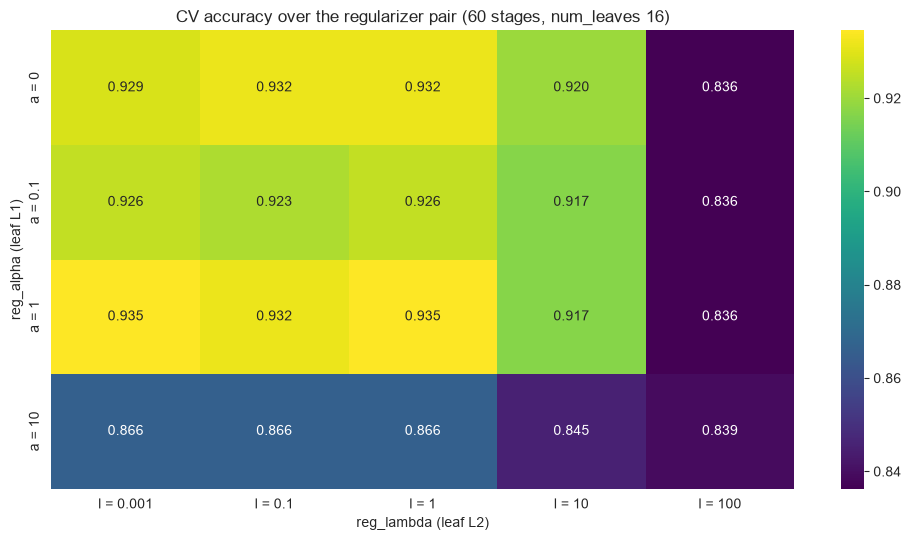

best cell: alpha = 1, lambda = 0.001  (CV acc 0.9345)

💡 Both regularizers start at 0 - LightGBM's regularizer is opt-in, where XGBoost
   ships lambda = 1. Small doses smooth the leaf values the greedy growth just
   wrote; heavy lambda underfits at only 60 stages, the same short-budget trap
   notebook 09's grid hit.


In [22]:
# reg_alpha x reg_lambda grid at fixed num_leaves = 16 - the two leaf regularizers,
# both OFF by default (unlike XGBoost, whose lambda ships at 1.0)
alpha_grid_lgb = [0.0, 0.1, 1.0, 10.0]
lam_grid_lgb = [0.001, 0.1, 1.0, 10.0, 100.0]
cv_al = StratifiedKFold(3, shuffle=True, random_state=42)
mat_al = np.zeros((len(alpha_grid_lgb), len(lam_grid_lgb)))
for i_al, a_lgb in enumerate(alpha_grid_lgb):
    for j_lgb, lam_lgb in enumerate(lam_grid_lgb):
        m_al = LGBMClassifier(num_leaves=16, n_estimators=60, learning_rate=0.1,
                              reg_alpha=a_lgb, reg_lambda=lam_lgb,
                              n_jobs=1, verbosity=-1, random_state=0)
        mat_al[i_al, j_lgb] = cross_val_score(m_al, Xt7_tr, yt7_tr, cv=cv_al,
                                              scoring="accuracy", n_jobs=-1).mean()

plot_al = pd.DataFrame(mat_al, index=alpha_grid_lgb, columns=lam_grid_lgb)
fig, ax_al = plt.subplots(figsize=(10, 5.5))
sns.heatmap(plot_al, annot=True, fmt=".3f", cmap="viridis", ax=ax_al,
            yticklabels=[f"a = {a_lgb:g}" for a_lgb in alpha_grid_lgb],
            xticklabels=[f"l = {lam_lgb:g}" for lam_lgb in lam_grid_lgb])
ax_al.set_xlabel("reg_lambda (leaf L2)")
ax_al.set_ylabel("reg_alpha (leaf L1)")
ax_al.set_title("CV accuracy over the regularizer pair (60 stages, num_leaves 16)")
plt.tight_layout()
plt.show()

best_cell_al = plot_al.stack().idxmax()
print(f"best cell: alpha = {best_cell_al[0]:g}, lambda = {best_cell_al[1]:g}"
      f"  (CV acc {plot_al.stack().max():.4f})")
print("\n💡 Both regularizers start at 0 - LightGBM's regularizer is opt-in, where XGBoost")
print("   ships lambda = 1. Small doses smooth the leaf values the greedy growth just")
print("   wrote; heavy lambda underfits at only 60 stages, the same short-budget trap")
print("   notebook 09's grid hit.")

### Early Stopping: A Stage Budget, Not a Target

Early stopping is a **callback** in LightGBM: `fit(..., eval_set=[...], callbacks=[lgb.early_stopping(stopping_rounds=k)])`. Training halts when the monitored metric stops improving, `best_iteration_` records the kept stage-count, and the wrapper's `predict`/`score` automatically read the best iteration (the native `Booster.predict` follows the same rule — notebook 09's native-API trap does not exist here). Related knobs: `first_metric_only` (drive ES on the first logged metric), `min_delta` (require real improvement, new in 4.4).

The docs' recommendation carries over unchanged: cross-validate to choose hyperparameters, then retrain the final model **on the full training data with early stopping** — ES inside CV changes the model's stage count per fold and muddies comparisons.

Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[70]	training's binary_logloss: 0.108541	valid_1's binary_logloss: 0.242353


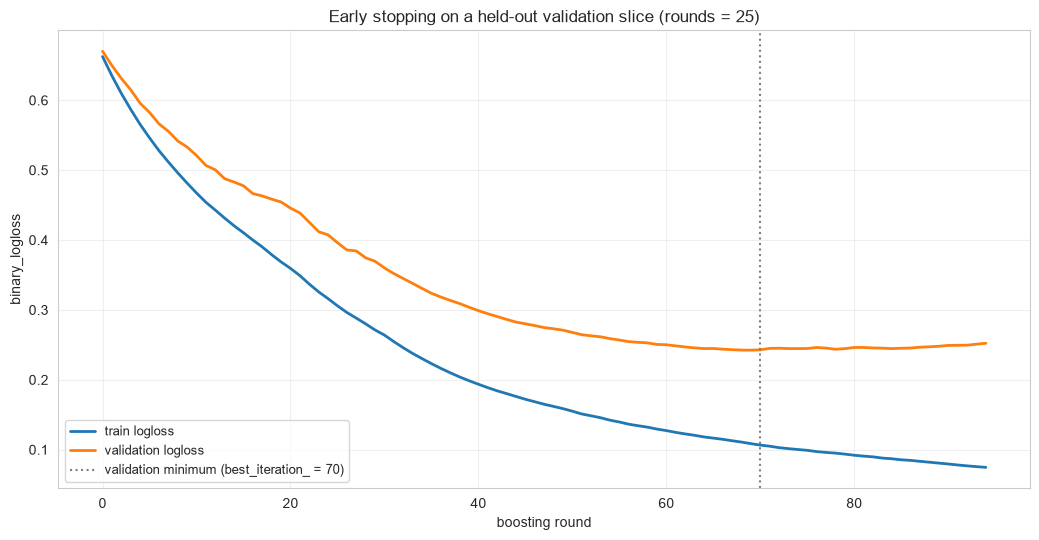

requested 600 rounds; early stopping saved best_iteration_ = 70
validation logloss at the minimum: 0.2424
test accuracy (wrapper predict auto-uses the best iteration): 89.6%

💡 The staged-loss curve tells the same story as notebooks 08/09: train keeps
   sinking, validation flattens then turns - and the callback turns the peak into
   the model automatically. n_estimators is a budget, never a target.


In [23]:
# Validation carved out of the TRAINING portion - the test set stays sealed
Xv7_tr, Xv7_val, yv7_tr, yv7_val = train_test_split(Xt7_tr, yt7_tr, test_size=0.2,
                                                    stratify=yt7_tr, random_state=42)

clf_es_lgb = LGBMClassifier(num_leaves=16, n_estimators=600, learning_rate=0.05,
                            verbosity=-1, random_state=0)
clf_es_lgb.fit(Xv7_tr, yv7_tr,
               eval_set=[(Xv7_tr, yv7_tr), (Xv7_val, yv7_val)],
               eval_metric="binary_logloss",
               callbacks=[lgb.early_stopping(stopping_rounds=25),
                          lgb.log_evaluation(period=0)])

# evals_result_ is a PROPERTY (the dict itself, no parentheses - XGBoost's read is a method)
history_lgb = clf_es_lgb.evals_result_
train_key_lgb, valid_key_lgb = list(history_lgb.keys())[:2]

fig, ax_es = plt.subplots(figsize=(10.5, 5.5))
ax_es.plot(history_lgb[train_key_lgb]["binary_logloss"], lw=2, label="train logloss")
ax_es.plot(history_lgb[valid_key_lgb]["binary_logloss"], lw=2, label="validation logloss")
ax_es.axvline(clf_es_lgb.best_iteration_, color="gray", ls=":", lw=1.5,
              label=f"validation minimum (best_iteration_ = {clf_es_lgb.best_iteration_})")
ax_es.set_xlabel("boosting round")
ax_es.set_ylabel("binary_logloss")
ax_es.set_title("Early stopping on a held-out validation slice (rounds = 25)")
ax_es.legend(fontsize=9)
ax_es.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"requested 600 rounds; early stopping saved best_iteration_ = "
      f"{clf_es_lgb.best_iteration_}")
print(f"validation logloss at the minimum: "
      f"{min(history_lgb[valid_key_lgb]['binary_logloss']):.4f}")
print(f"test accuracy (wrapper predict auto-uses the best iteration): "
      f"{clf_es_lgb.score(Xt7_te, yt7_te):.1%}")
print("\n💡 The staged-loss curve tells the same story as notebooks 08/09: train keeps")
print("   sinking, validation flattens then turns - and the callback turns the peak into")
print("   the model automatically. n_estimators is a budget, never a target.")

---

## 8. Complete Hyperparameter Reference

### LGBMClassifier Parameters (lightgbm 4.6.0)

The wrapper's names are the native primary names; everything in the native registry passes through `**kwargs` (parameters merge in the documented order — LightGBM's defaults, then your `**kwargs`, so your values win). Defaults below are the pinned version's own, from `get_params()` and the parameter reference.

#### `num_leaves` (int, default=31) **[THE HYPERPARAMETER]**
- **Description**: max leaves in one tree — the shape budget the leaf-wise grower spends greedily
- **Effect**: the leaf-wise analog of notebook 09's `max_depth`: more leaves = more expression per stage and a deeper effective reach (§5's shape study); the docs' constraint is $1 < \mathrm{num\_leaves} \le 131072$
- **Tuning strategy**: the first value on small datasets; keep it in the low tens unless data is plentiful (§7 sweep); the tuning guide pairs it with `min_child_samples`
- **Example**: `LGBMClassifier(num_leaves=16)` for a few thousand rows

#### `learning_rate` (float, default=0.1, aliases: `eta`, `shrinkage_rate`) **[THE OTHER HALF]**
- **Description**: step-size shrinkage ν on every stage's contribution
- **Effect**: small η → smooth accumulation, needs stages; big η → fast, sloppy (§7 sweep)
- **Example**: `LGBMClassifier(learning_rate=0.05, n_estimators=500)` + early stopping

#### `n_estimators` (int, default=100, native aliases: `num_iterations`, `num_boost_round`) **[THE OTHER HALF]**
- **Description**: stage count B. With an early-stopping callback it is a budget, not a target
- **Note**: for multiclass, LightGBM constructs `num_class × num_iterations` trees
- **Example**: `n_estimators=1000` with `callbacks=[lgb.early_stopping(25)]`

#### `max_depth` (int, default=-1)
- **Description**: a CAP on how deep leaf-wise growth may reach ("limit the max depth... Tree still grows leaf-wise"; ≤ 0 = no limit)
- **Effect**: emergency brake on the asymmetric branches; NOT the growth template
- **Example**: `max_depth=8` to bound effective depth on tiny data

#### `min_child_samples` (int, default=20, aliases: `min_data_in_leaf`, `min_samples_leaf`)
- **Description**: the row-count leaf floor — a leaf must hold at least this many rows to be cut again
- **Effect**: the primary small-data brake: with 168 rows the default 20 caps even the default num_leaves=31 near 8 (§6's trees_to_dataframe read)
- **Example**: `min_child_samples=5` on a few hundred rows

#### `min_child_weight` (float, default=1e-3, aliases: `min_sum_hessian_in_leaf`)
- **Description**: the hessian-mass leaf floor ($\sum h_i$ per leaf)
- **Effect**: notebook 09's `min_child_weight`, finer-grained; binds before the row floor only on plentiful data (§7)
- **Warning**: NOT the row floor — that is `min_child_samples`. XGBoost's `min_child_weight` means the same hessian floor; the 1e-3 default here is effectively idle, so XGBoost-tuned values rarely transfer
- **Example**: `min_child_weight=10` once rows are plentiful

#### `min_split_gain` (float, default=0.0, alias: `min_gain_to_split`)
- **Description**: the split toll — a candidate split must earn more gain than this
- **Example**: `min_split_gain=0.1` for greedy-noise pruning

#### `subsample` (float, default=1.0, aliases: `bagging_fraction`, `bagging`) + **`subsample_freq`** (int, default=0, aliases: `bagging_freq`)
- **Description**: row bagging — a **fraction** of rows sampled every `subsample_freq`'th round
- **⚠ THE GOTCHA**: bagging is only effective when `bagging_freq > 0` **AND** `bagging_fraction < 1.0`; setting `subsample=0.8` alone is silently inert (XGBoost's `subsample` runs alone — §7's demo)
- **Example**: `subsample=0.8, subsample_freq=1` to actually bag

#### `colsample_bytree` (float, default=1.0, alias: `feature_fraction`)
- **Description**: fraction of features sampled per tree — **no frequency key needed**
- **Example**: `colsample_bytree=0.7` for wide feature spaces

#### `reg_lambda` (float, default=0.0, aliases: `lambda_l2`, `lambda`) / `reg_alpha` (float, default=0.0, alias: `lambda_l1`)
- **Description**: L2 / L1 penalties on leaf values — the identical $w^* = -G/(H+\lambda)$ algebra of notebooks 08–10, with α applied to the leaf's magnitude
- **Effect**: both default to **0** — XGBoost ships λ = 1; LightGBM leans on the leaf floors instead and leaves the regularizers to you (§7's grid)
- **Example**: `reg_lambda=1.0` as the first regularizer to try

#### `data_sample_strategy` (str, default=`bagging`; `bagging`, `goss`) **[native-only, new in 4.0]**
- **Description**: which row-sampling strategy the boosting loop runs. `bagging` becomes active only per the `subsample`/`subsample_freq` note above; **`goss`** keeps all large-|g| rows (`top_rate`, default 0.2), random-samples the rest (`other_rate`, default 0.1) and reweights them by $(1-a)/b$
- **Example**: `LGBMClassifier(data_sample_strategy="goss")` on millions of rows

#### `max_bin` (int, default=255) **[native-only]**
- **Description**: max bins per feature for the histograms every split search consumes
- **Effect**: smaller bins → faster, slightly coarser splits; larger → finer cuts, slower
- **Note**: features are quantized once on the `Dataset`
- **Example**: `max_bin=63` for throughput, `max_bin=511` to chase precision

#### `verbosity` (int, default=1, alias: `verbose`) **[native-only]**
- **Description**: log level: < 0 fatal only, 0 = warnings and errors, 1 = Info (the [LightGBM] lines you see), > 1 debug
- **Example**: `verbosity=-1` in notebooks; `callbacks=[lgb.log_evaluation(period=0)]` as the per-round alternative

#### `num_threads` (int, default=0; wrapper: `n_jobs=None`)
- **Description**: 0 = "default number of threads in OpenMP", i.e. every core
- **Note**: set `n_jobs = 1` for the estimator inside a parallel sklearn sweep (§7); do not change num_threads mid-life of a process running jobs
- **Example**: `GridSearchCV(LGBMClassifier(n_jobs=1, ...), cv, n_jobs=-1)`

#### `enable_bundle` (bool, default=`true`, alias: `bundle`) **[native-only]**
- **Description**: exclusive feature bundling (EFB) — mostly-non-overlapping sparse features fused into one column before training
- **Effect**: free speed on one-hot / sparse blocks; the reason LightGBM eats wide sparse spaces
- **Note**: `max_conflict_rate` (default 0.0) relaxes the exclusivity rule — features that occasionally overlap may still bundle, at a (usually small) accuracy cost

#### Categorical parameters (native-side): `max_cat_threshold` (32), `min_data_per_group` (100), `cat_l2` (10.0), `cat_smooth` (10.0), `max_cat_to_onehot` (4)
- **Description**: the categorical machinery of §3 — candidate partitions per category ordering; one-vs-other splits below `max_cat_to_onehot` categories; smoothing for small groups
- **Example**: `cat_smooth=20` on data where tiny categories look too strong

#### `objective` (str, default=None → auto per task)
- **Description**: the loss via the wrapper's inference, or explicit — `binary`, `multiclass` (+ `num_class`), `regression` (L2), `regression_l1` (MAE), `huber`, `quantile` (+ `alpha`), `poisson`, `cross_entropy`... The native binary objective requires labels in {0, 1}
- **Example**: `LGBMRegressor(objective="regression_l1")` for outlier-robust fits

#### `boosting_type` (str, default=`gbdt`; `gbdt`, `rf`, `dart`)
- **Description**: the base-learner family. `dart` adds dropout between trees (drop_rate 0.1, skip_drop 0.5) — a stochastic-ish regularizer with slower inference; `rf` turns LightGBM into a random forest (needs `bagging_freq`)
- **Example**: `boosting_type="dart"` for a last-mile accuracy squeeze when inference budget allows

#### `seed` hierarchy (native)
- The docs: `seed` (default None) generates the other seeds (data/feature-fraction/bagging/dropout) but has **lower priority** — explicitly-set other seeds override it; `deterministic=true` stabilizes across runs at a training-speed cost
- **Example**: `seed=42` for reproducible sweeps, `deterministic=True` when exact reruns matter

#### `eval_metric` (str or list, default per objective)
- **Description**: validation metrics for the `evals_result_` history and early stopping — `binary_logloss`, `auc`, `average_precision`; `l2`, `rmse`, `l1`, `mape` for regression
- **Example**: `eval_metric=["binary_logloss", "auc"]` + `first_metric_only=True`

### Fitted Attributes Worth Knowing

- `best_iteration_` — the early-stopping verdict, **with** the trailing underscore (XGBoost keeps none); wrapper predictions read it automatically when it exists
- `evals_result_` — the per-round metric history, a **property** (attribute access, no parentheses — unlike XGBoost's `evals_result()` method) captured internally via the same `lgb.record_evaluation` recorder the native API exposes; keys follow the `eval_set` order
- `feature_importances_` — normalized `importance_type` (default **split**) importances; forwarded to the booster's `feature_importance`
- `booster_` — the native engine (`num_trees()`, `feature_importance`, `trees_to_dataframe()`); its eval history comes from `lgb.record_evaluation`, not a Booster method
- `trees_to_dataframe()` — the parsed structure: split nodes carry `split_feature`/`threshold`/`split_gain`/`left_child`, leaves are the rows where those are **null**; `node_depth` counts from the root at 1, `value` is the (shrunk) leaf value, `weight` the leaf's hessian mass, `count` its rows, and `missing_direction` shows the learned NaN route
- `classes_` — the wrapper's sorted-unique class labels (arbitrary input labels are LabelEncoded for the native engine)

### What the Family Twin Covers

| LightGBM parameter | Scratch twin (`GradientBoostingClassifierScratch`) | Notes |
|---|---|---|
| `n_estimators`, `learning_rate` | ✅ | identical meaning; shrinkage once per stage |
| $F_0$ / `boost_from_average` | ✅ | same base-rate constant (`_f0_logit`) |
| leaf values $-G/(H+\lambda)$ | ✅ at λ=0 | `_newton_leaf_values`; λ hand-built in §5 |
| `num_leaves`, leaf-wise growth | ❌ (hand-built §5) | the twin's trees are depth-first on residuals |
| `min_child_samples` / `min_child_weight` / `min_split_gain` | ❌ | no gates in the twin's split search |
| GOSS, `subsample`, `colsample_bytree` | ❌ (GOSS hand-built §5) | no stochastic stages; `random_state` unused |
| `max_bin`, EFB, native categoricals, NaN routing | ❌ | the compiled engine's contributions |
| eval history, early stopping, callbacks | ❌ | no per-round logloss tracked to stop on |

### Parameter Combination Recipes

#### Baseline for small-to-medium data (start here):
```python
LGBMClassifier(num_leaves=16, learning_rate=0.1, n_estimators=200,
               verbosity=-1, random_state=42)
```

#### The stage-budget shape (production default):
```python
LGBMClassifier(num_leaves=16, learning_rate=0.05, n_estimators=1000,
               verbosity=-1, random_state=42)
# fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
#     callbacks=[lgb.early_stopping(25), lgb.log_evaluation(0)])
```

#### Large data:
```python
LGBMClassifier(num_leaves=127, max_bin=255, n_jobs=-1)
# fit(callbacks=[lgb.early_stopping(25)])   # callbacks belong to fit, not the constructor
```

#### Wide / sparse feature spaces (the paper's showcase):
```python
LGBMClassifier(data_sample_strategy="goss", enable_bundle=True, n_jobs=-1)
```

#### Native categoricals:
```python
# cast the column first: df["tier"] = df["tier"].astype("category")
LGBMClassifier()  # category dtypes are picked up automatically
```

#### Imbalanced classes:
```python
LGBMClassifier(class_weight="balanced")
```

#### Random forest mode / dart booster:
```python
LGBMClassifier(boosting_type="rf", bagging_freq=1, bagging_fraction=0.8)
LGBMClassifier(boosting_type="dart", drop_rate=0.15, skip_drop=0.4)
```

#### Regression variants:
```python
LGBMRegressor(objective="regression_l1")                       # outlier-robust (MAE)
LGBMRegressor(objective="quantile", alpha=0.9)                 # 90th-percentile fit
LGBMRegressor(objective="poisson")                             # counts
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Budget `num_leaves` Before Anything Else**
The growth policy's currency is the leaf. Keep the budget in the low tens on small data; let the leaf floors (`min_child_samples`, then `min_child_weight`) police the greedy frontier — that is the LightGBM-tuned-trio (§7).

#### 2. **Let Early Stopping Hold the Stopwatch**
```python
clf = LGBMClassifier(num_leaves=16, learning_rate=0.05, n_estimators=1000, verbosity=-1)
clf.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(25), lgb.log_evaluation(0)])
```
Cross-validate to choose knobs, then ES-retrain on the full training data (§7). The wrapper picks up `best_iteration_` for predictions automatically.

#### 3. **Remember Bagging Has Two Keys**
`subsample` alone does nothing — set `subsample_freq > 0` alongside it. If a ported XGBoost config bagged without the frequency key, it was not bagging (§7's gotcha demo).

#### 4. **Search η, λ, α on Log Grids**
All three act multiplicatively; a linear grid wastes resolution where you need it (§7 heatmaps).

#### 5. **Read `split` and `gain` Importances Together**
LightGBM defaults every importance read to **split** (frequency) — the rough-opposite of XGBoost's wrapper default (`gain`). Before removing a feature on one number, check the other type and pair with `permutation_importance` as in notebooks 04/08/09.

#### 6. **Give `n_jobs` Where the Parallelism Lives**
LightGBM uses every core by default (`num_threads = 0`). Inside `GridSearchCV(n_jobs=-1)`, give LightGBM `n_jobs=1` — the outer sweep owns the cores.

#### 7. **Cast Categories, Don't One-Hot Blindly**
pandas `category` dtype is all the declaration needed (§3). High cardinality with few rows per category still needs `cat_smooth`/`min_data_per_group` — native handling is an economy, not a license.

#### 8. **Silence Per-Iteration Logs in Runs and Sweeps**
`verbosity=-1` (or `callbacks=[lgb.log_evaluation(period=0)]`) keeps CV logs readable; leave verbosity at defaults when diagnosing.

### ❌ Common Mistakes

#### 1. **The Inert `subsample`**
```python
# BAD:  LGBMClassifier(subsample=0.8).fit(X, y)                # bagged nothing
# GOOD: LGBMClassifier(subsample=0.8, subsample_freq=1).fit(X, y)
```

#### 2. **Treating `max_depth` as the Complexity Knob** (an XGBoost reflex)
```python
# BAD:  LGBMClassifier(max_depth=3, num_leaves=2**8)           # depth is only a cap
# GOOD: LGBMClassifier(num_leaves=8)                           # the budget IS the knob
```
When both are set, `max_depth` is the structural ceiling — a binary tree of depth $d$ can hold at most $2^d$ leaves, so the tighter of the two knob limits wins.

#### 3. **Big `num_leaves` on Small Data**
```python
# BAD:  LGBMClassifier().fit(X_300rows, y)     # 31 leaves default on ~300 rows
# GOOD: LGBMClassifier(num_leaves=8, min_child_samples=5).fit(X_300rows, y)
```

#### 4. **Migrating `min_child_weight` Literals**
In LightGBM it is the hessian floor (1e-3 default); the XGBoost-tuned `min_child_weight=5` should usually become `min_child_samples=5` here.

#### 5. **Tuning on the Test Set**
```python
# BAD:  best num_leaves = the budget where TEST accuracy peaked               (leaked)
# GOOD: CV on training data; the test set reports once
```

#### 6. **Trusting `feature_importances_` as Causal**
All split-type importances (notebook 04's bias, sharpened by greedy leaf-wise growth) inflate features that split often on lucky ties — read both importance types, verify with permutation.

#### 7. **Early Stopping Without `eval_set`**
```python
# BAD:  callbacks=[lgb.early_stopping(25)] but no eval_set     (nothing to watch)
# GOOD: fit(..., eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(25)])
```

#### 8. **One-Hotting Everything Out of Habit**
One-hot blocks cost columns, splits, and calibration — §3's demo showed a tier column eating its one-hot rival on the same data. Cast to `category` first.

#### 9. **Labels the Native Path Cannot Sort**
Native `binary` requires {0, 1} labels; feed strings to the native API and it fails loudly. The wrapper LabelEncodes — know which door you are in.

### Debugging Recipes

#### Training Is Painfully Slow?
1. Lower `max_bin`; cut per-stage row cost with `data_sample_strategy="goss"`; for proof-of-concept speed, `subsample=0.6, subsample_freq=1` and `colsample_bytree=0.7`
2. Check `n_jobs` on the estimator and the outer sweep — one of them should own the cores
3. Frequent `Dataset` re-construction is the usual hidden cost — create once, train repeatedly

#### Train Accuracy 1.0, Validation Curling Up?
1. Overfitting: smaller `num_leaves`, raise `min_child_samples`, add `reg_lambda`, enable bagging (`subsample=0.8, subsample_freq=1`)
2. Early stopping on a carved validation slice — read where the curve bottoms
3. Check label noise; boosting chases residuals (notebook 08)

#### Both Curves Low and Flat?
1. Underfitting: raise `num_leaves` (and η then stages)
2. Verify `eval_metric` matches the decision (logloss vs auc vs accuracy)
3. Confirm the categorical columns actually arrived as `category` dtype (§3): plain string columns are refused outright, while numeric columns survive silently as numeric codes — check `feature_name_` and the printed category list before trusting a sweep

#### `[LightGBM] [Info]` Lines Everywhere?
1. `verbosity=-1` on estimator construction, or `callbacks=[lgb.log_evaluation(0)]` at fit
2. Leave one Info run on when *diagnosing* — the printed bin/leaf counts are structure, not noise

#### "categorical_feature in Dataset is overridden..."?
1. The data's category dtypes and an explicit `categorical_feature` argument disagree
2. Cast once with `astype("category")` and pass nothing, or align the explicit list with the dtype — never both half-way

---

## 10. Real-world Examples

Two examples chosen as a **pair of contrasts**, the same protocol budgets as notebook 09 so the three library chapters stay comparable:

- **Example 1: Breast Cancer Diagnosis (binary, medical).** The decision is clinical and the costly error is a missed malignant tumor. Workflow: a compact grid search (no early stopping inside CV), then a final retrain **with** the early-stopping callback on a carved validation slice, per-class reporting, and the probability read with a Brier score.
- **Example 2: Diabetes Progression (regression, 10 baseline variables).** `load_diabetes` is bundled, real, and small. The regressor mirror: an ES budget, the honest test read (R², RMSE), gain importances, and the predictions-vs-truth picture that shows the clamping.

Both datasets ship with scikit-learn; no downloads.

In [24]:
# Example 1: breast cancer diagnosis - compact grid, then the ES retrain
bc10 = load_breast_cancer()
Xbc10_tr, Xbc10_te, ybc10_tr, ybc10_te = train_test_split(
    bc10.data, bc10.target, test_size=0.25, stratify=bc10.target, random_state=42
)

param_grid_bc10 = {"learning_rate": [0.03, 0.1, 0.3], "num_leaves": [8, 31]}
gs_bc10 = GridSearchCV(
    LGBMClassifier(n_estimators=150, n_jobs=1, verbosity=-1, random_state=42),
    param_grid_bc10,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    n_jobs=-1,
)
gs_bc10.fit(Xbc10_tr, ybc10_tr)
best_bc10 = gs_bc10.best_params_
print(f"best CV accuracy: {gs_bc10.best_score_:.1%} with {best_bc10}")

# Retrain with early stopping on the full training data (validation carved from train only)
Xbc10_fit, Xbc10_val, ybc10_fit, ybc10_val = train_test_split(
    Xbc10_tr, ybc10_tr, test_size=0.15, stratify=ybc10_tr, random_state=42
)
final_bc10 = LGBMClassifier(num_leaves=best_bc10["num_leaves"],
                            learning_rate=best_bc10["learning_rate"],
                            n_estimators=1000, verbosity=-1, random_state=42)
final_bc10.fit(Xbc10_fit, ybc10_fit,
               eval_set=[(Xbc10_val, ybc10_val)],
               eval_metric="binary_logloss",
               callbacks=[lgb.early_stopping(stopping_rounds=25),
                          lgb.log_evaluation(period=0)])
pred_bc10 = final_bc10.predict(Xbc10_te)

print(f"early stopping saved best_iteration_ = {final_bc10.best_iteration_} of 1000")
print(f"test accuracy: {final_bc10.score(Xbc10_te, ybc10_te):.1%}")

cm_bc10 = confusion_matrix(ybc10_te, pred_bc10)
print("\nClassification report (benign = positive class, sklearn's convention):")
print(classification_report(ybc10_te, pred_bc10, target_names=["malignant (0)", "benign (1)"]))
print(f"confusion matrix rows = true, columns = predicted: {cm_bc10.tolist()}")
print(f"missed malignant tumors (predicted benign): {cm_bc10[0, 1]} of {cm_bc10[0].sum()}")

best CV accuracy: 97.2% with {'learning_rate': 0.1, 'num_leaves': 31}
Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[44]	valid_0's binary_logloss: 0.0763855
early stopping saved best_iteration_ = 44 of 1000
test accuracy: 95.8%

Classification report (benign = positive class, sklearn's convention):
               precision    recall  f1-score   support

malignant (0)       0.98      0.91      0.94        53
   benign (1)       0.95      0.99      0.97        90

     accuracy                           0.96       143
    macro avg       0.96      0.95      0.95       143
 weighted avg       0.96      0.96      0.96       143

confusion matrix rows = true, columns = predicted: [[48, 5], [1, 89]]
missed malignant tumors (predicted benign): 5 of 53


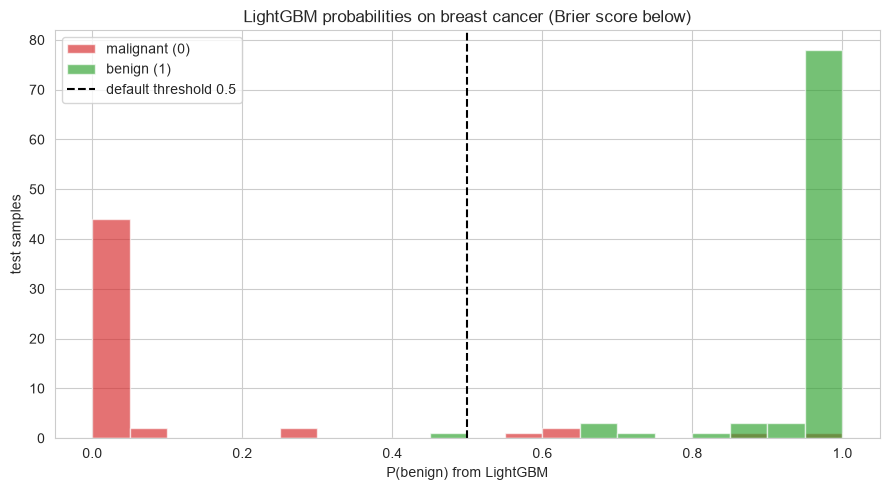

Brier score: 0.0263  (0 = perfect probabilities, 0.25 = uninformed)

💡 Same reading as notebooks 08/09's Example 1, one engine later: the p = 0.5
   cut is a choice. For a screening task a clinic might act at P(malignant) > 0.2,
   trading false alarms for fewer missed cancers - priced by the confusion matrix.


In [25]:
# ...and the probability read: where do the two classes' scores land?
proba_bc10 = final_bc10.predict_proba(Xbc10_te)[:, 1]      # P(benign)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(proba_bc10[ybc10_te == 0], bins=np.linspace(0, 1, 21), alpha=0.65,
        color="#d62728", label="malignant (0)")
ax.hist(proba_bc10[ybc10_te == 1], bins=np.linspace(0, 1, 21), alpha=0.65,
        color="#2ca02c", label="benign (1)")
ax.axvline(0.5, color="k", ls="--", lw=1.5, label="default threshold 0.5")
ax.set_xlabel("P(benign) from LightGBM")
ax.set_ylabel("test samples")
ax.set_title("LightGBM probabilities on breast cancer (Brier score below)")
ax.legend()
plt.tight_layout()
plt.show()

brier_bc10 = brier_score_loss(ybc10_te, proba_bc10)
print(f"Brier score: {brier_bc10:.4f}  (0 = perfect probabilities, 0.25 = uninformed)")
print("\n💡 Same reading as notebooks 08/09's Example 1, one engine later: the p = 0.5")
print("   cut is a choice. For a screening task a clinic might act at P(malignant) > 0.2,")
print("   trading false alarms for fewer missed cancers - priced by the confusion matrix.")

### Example 2: Diabetes Progression (Regression)

442 patients × 10 baseline variables (the features arrive pre-standardized), target = disease progression one year out. `LGBMRegressor` with an ES budget; the test read is R² and RMSE, the inspection tools are gain importances and the predictions-vs-truth picture.

Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[39]	valid_0's l2: 3595.48
early stopping saved best_iteration_ = 39 of 1000
test R²:   0.4764
test RMSE: 53.8098


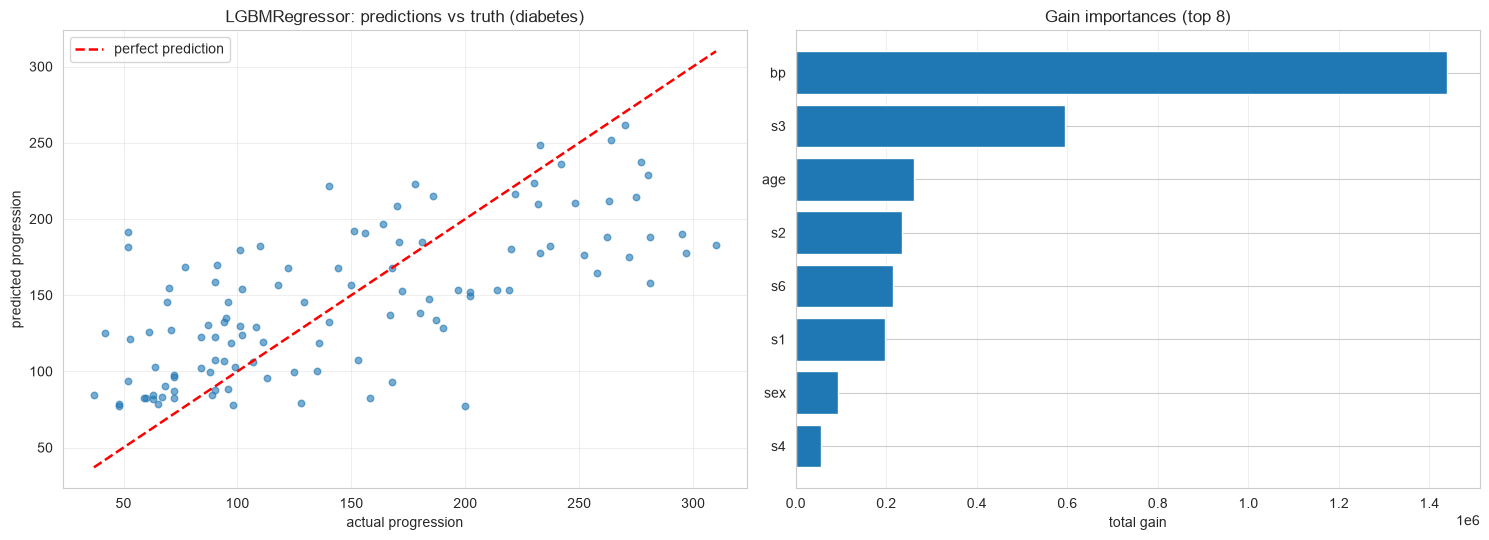


top-3 gain features: ['bmi', 's5', 'bp']

💡 The predictions clamp to the training range at the extremes - trees cannot
   extrapolate (notebook 04's warning, priced in real units here). The strongly
   correlated clinical picture from notebooks 08/09 reappears: the gains ride on a
   small set of features for this small, well-conditioned regression problem.


In [26]:
# Example 2: diabetes progression - LGBMRegressor with an ES budget
diabetes10 = load_diabetes()
Xdi10 = pd.DataFrame(diabetes10.data, columns=diabetes10.feature_names)
ydi10 = diabetes10.target

Xdi10_tr, Xdi10_te, ydi10_tr, ydi10_te = train_test_split(
    Xdi10, ydi10, test_size=0.25, random_state=42
)
Xdi10_fit, Xdi10_val, ydi10_fit, ydi10_val = train_test_split(
    Xdi10_tr, ydi10_tr, test_size=0.2, random_state=42
)

final_di10 = LGBMRegressor(num_leaves=16, learning_rate=0.05, n_estimators=1000,
                           verbosity=-1, random_state=42)
final_di10.fit(Xdi10_fit, ydi10_fit,
               eval_set=[(Xdi10_val, ydi10_val)],
               eval_metric="l2",
               callbacks=[lgb.early_stopping(stopping_rounds=25),
                          lgb.log_evaluation(period=0)])
pred_di10 = final_di10.predict(Xdi10_te)

print(f"early stopping saved best_iteration_ = {final_di10.best_iteration_} of 1000")
print(f"test R²:   {r2_score(ydi10_te, pred_di10):.4f}")
print(f"test RMSE: {np.sqrt(mean_squared_error(ydi10_te, pred_di10)):.4f}")

gain_di10 = pd.Series(
    final_di10.booster_.feature_importance(importance_type="gain"),
    index=final_di10.booster_.feature_name(),
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(ydi10_te, pred_di10, alpha=0.6, s=22, color="#1f77b4")
lims_di = [min(ydi10_te.min(), pred_di10.min()), max(ydi10_te.max(), pred_di10.max())]
axes[0].plot(lims_di, lims_di, "r--", lw=1.8, label="perfect prediction")
axes[0].set_xlabel("actual progression")
axes[0].set_ylabel("predicted progression")
axes[0].set_title("LGBMRegressor: predictions vs truth (diabetes)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].barh(gain_di10.index[::-1][:8], gain_di10.values[::-1][:8], color="#1f77b4")
axes[1].set_xlabel("total gain")
axes[1].set_title("Gain importances (top 8)")
axes[1].grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\ntop-3 gain features: {list(gain_di10.head(3).index)}")
print("\n💡 The predictions clamp to the training range at the extremes - trees cannot")
print("   extrapolate (notebook 04's warning, priced in real units here). The strongly")
print("   correlated clinical picture from notebooks 08/09 reappears: the gains ride on a")
print("   small set of features for this small, well-conditioned regression problem.")

---

## 11. Comparison with Other Algorithms

### When to Choose LightGBM vs Alternatives

| Aspect | LightGBM | XGBoost (nb 09) | HistGradientBoosting | GradientBoosting (sklearn) | Random Forest |
|---|---|---|---|---|---|
| **Growth policy** | leaf-wise, `num_leaves` budget | level-wise (`lossguide` optional) | best-first heap, `max_leaf_nodes` | depth-limited full trees | depth-limited random subsets |
| **Split candidates** | histograms (`max_bin` 255) | histograms (`tree_method="hist"`) | histograms (`max_bins` 255) | raw value scan | raw value scan |
| **Leaf algebra** | $-G/(H+\lambda)$, λ default **0** | $-G/(H+\lambda)$, λ default **1**, γ inside the gain | Newton step (λ = 0) | Friedman tweak on the Newton step¹ | leaf means / votes |
| **NaN handling** | native route | native (learned direction) | native | raises | imputation needed |
| **Categoricals** | native (`category` dtype) | `enable_categorical` | `categorical_features` param | encode first | encode first |
| **Row sampling** | `subsample` **+** `subsample_freq` (windowed bagging) | `subsample` alone | `subsample` (< 1.0) | `subsample` | bootstrap + `max_features` |
| **GOSS / EFB** | ✅ both, first-class | ✖ (gradient-based sampling mode exists) | ✖ | ✖ | ✖ |
| **Multiclass** | K trees per round | K trees per stage | one-vs-rest internals | softmax deviance (K trees/stage) | vote fractions |
| **Early stopping** | callbacks + `eval_set` | constructor + `eval_set` | `early_stopping` param | `n_iter_no_change` trio | none (OOB instead) |
| **Default fit on small data** | can overfit (num_leaves 31; floors hold it) | can overfit (η 0.3, depth 6) | gentle | gentle (η 0.1) | very robust |
| **Speed at scale** | ⭐⭐⭐⭐⭐ (hist + GOSS + EFB + threads) | ⭐⭐⭐⭐⭐ (hist + threads/GPU) | ⭐⭐⭐⭐ | ⭐⭐ (exact splits) | ⭐⭐⭐⭐ (parallel) |
| **Serialization** | `save_model` (text/JSON) | JSON `save_model` | pickle-only | pickle-only | pickle-only |

¹ shared skeleton — notebook 08 §6's dual-engine analysis shows exactly where the two differ.

The **growth-policy line** is the fork LightGBM pushed: a leaf budget spent greedily is the shape knob, GOSS and EFB price the *data* side, and both default regularizers sit at zero — a "spend freely, gate the leaves" philosophy opposite XGBoost's "price everything upfront". HistGradientBoosting is the best-first idea inside sklearn itself; CatBoost (notebook 11) takes the categorical line further.

### Practical Comparison

The same 5-fold CV protocol as notebooks 05/08/09 on three geometries. LightGBM and XGBoost both run `n_jobs=1` (their cores belong to the outer CV sweep).

In [27]:
bc_cmp = load_breast_cancer()
datasets_cmp = {
    "blobs (3-class)": make_blobs(n_samples=600, centers=3, cluster_std=2.0, random_state=0),
    "moons (noisy)": make_moons(n_samples=600, noise=0.25, random_state=0),
    "breast cancer": (bc_cmp.data, bc_cmp.target),
}


def fresh_engines():
    # LightGBM n_jobs=1: the core budget belongs to cross_val_score's n_jobs=-1 (same
    # anti-thrashing arrangement as XGBoost in notebook 09)
    return {
        "LightGBM": LGBMClassifier(num_leaves=16, learning_rate=0.1, n_estimators=100,
                                   n_jobs=1, verbosity=-1, random_state=0),
        "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                 n_jobs=1, random_state=0),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=3, random_state=0),
        "GradientBoosting (sklearn)": GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.1, random_state=0),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    }


cv_cmp = StratifiedKFold(5, shuffle=True, random_state=0)
rows_cmp = []
for ds_name, (X_c, y_c) in datasets_cmp.items():
    for m_name, est_c in fresh_engines().items():
        t0 = time.perf_counter()
        scores_c = cross_val_score(est_c, X_c, y_c, cv=cv_cmp,
                                   scoring="accuracy", n_jobs=-1)
        rows_cmp.append({"model": m_name, "dataset": ds_name,
                         "mean": scores_c.mean(), "std": scores_c.std(),
                         "cv time (s)": time.perf_counter() - t0})

df_cmp = pd.DataFrame(rows_cmp).pivot(index="model", columns="dataset", values="mean")
df_cmp = df_cmp[["blobs (3-class)", "moons (noisy)", "breast cancer"]]
print(df_cmp.round(3).to_string())

lgb_row_cmp = df_cmp.loc["LightGBM"]
xgb_row_cmp = df_cmp.loc["XGBoost"]
hist_row_cmp = df_cmp.loc["HistGradientBoosting"]
print(f"\nLightGBM beats its accuracy twin XGBoost on "
      f"{int((lgb_row_cmp > xgb_row_cmp).sum())} of 3 geometries;"
      f" vs HistGB: {int((lgb_row_cmp > hist_row_cmp).sum())} of 3 (mean CV accuracy)")
times_cmp = pd.DataFrame(rows_cmp).groupby("model")["cv time (s)"].mean().round(2)
print(times_cmp.to_string())
print("\n💡 The margins are tiny and geometry-dependent - which is the honest summary:")
print("   at these sizes a well-tuned engine of this family lands within noise of any")
print("   other one, and the LightGBM-vs-XGBoost-vs-HistGB decision is usually about the")
print("   data shape (categories, sparsity, scale) and defaults, not a fixed winner.")

dataset                     blobs (3-class)  moons (noisy)  breast cancer
model                                                                    
GradientBoosting (sklearn)            0.692          0.928          0.965
HistGradientBoosting                  0.672          0.925          0.972
LightGBM                              0.655          0.928          0.968
Random Forest                         0.637          0.925          0.967
XGBoost                               0.675          0.937          0.974

LightGBM beats its accuracy twin XGBoost on 0 of 3 geometries; vs HistGB: 1 of 3 (mean CV accuracy)
model
GradientBoosting (sklearn)    0.36
HistGradientBoosting          0.15
LightGBM                      0.08
Random Forest                 0.44
XGBoost                       0.10

💡 The margins are tiny and geometry-dependent - which is the honest summary:
   at these sizes a well-tuned engine of this family lands within noise of any
   other one, and the LightGBM-vs-XGBoost-v

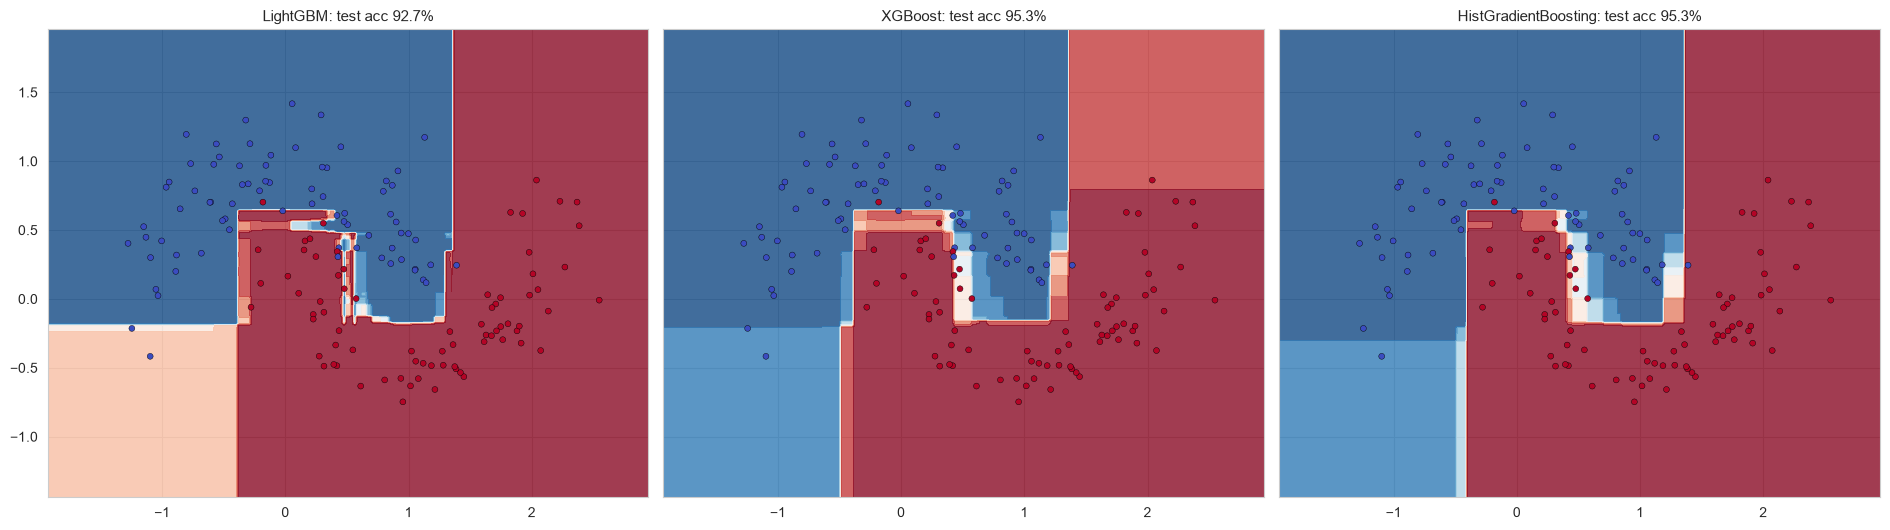


💡 Same moons, three engines of the same family: LightGBM's leaf-wise budget cut
   leaves where the ridge gets sharp, the level-wise siblings made rounder steps.
   On 350 training rows the boundaries differ in texture more than in accuracy -
   the shape economics show their full value when the data is much larger.


In [28]:
X_bd11, y_bd11 = make_moons(n_samples=500, noise=0.22, random_state=42)
Xbd11_tr, Xbd11_te, ybd11_tr, ybd11_te = train_test_split(X_bd11, y_bd11, test_size=0.3,
                                                          stratify=y_bd11, random_state=42)
families_bd11 = fresh_engines()

pad_bd = 0.4
xx_bd, yy_bd = np.meshgrid(
    np.linspace(X_bd11[:, 0].min() - pad_bd, X_bd11[:, 0].max() + pad_bd, 230),
    np.linspace(X_bd11[:, 1].min() - pad_bd, X_bd11[:, 1].max() + pad_bd, 230),
)
grid_bd = np.c_[xx_bd.ravel(), yy_bd.ravel()]

fig, axes_bd = plt.subplots(1, 3, figsize=(19, 5.4), sharey=True)
for ax_bd, name_bd in zip(axes_bd, ["LightGBM", "XGBoost", "HistGradientBoosting"]):
    est_bd = families_bd11[name_bd].fit(Xbd11_tr, ybd11_tr)
    Z_bd = est_bd.predict_proba(grid_bd)[:, 1].reshape(xx_bd.shape)
    ax_bd.contourf(xx_bd, yy_bd, Z_bd, levels=np.linspace(0.0, 1.0, 11),
                   cmap="RdBu_r", alpha=0.8)
    ax_bd.scatter(Xbd11_te[:, 0], Xbd11_te[:, 1], c=ybd11_te, cmap="coolwarm", s=18,
                  edgecolors="k", linewidths=0.3)
    ax_bd.set_title(f"{name_bd}: test acc {est_bd.score(Xbd11_te, ybd11_te):.1%}", fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Same moons, three engines of the same family: LightGBM's leaf-wise budget cut")
print("   leaves where the ridge gets sharp, the level-wise siblings made rounder steps.")
print("   On 350 training rows the boundaries differ in texture more than in accuracy -")
print("   the shape economics show their full value when the data is much larger.")

---

## 12. References

### 📚 Academic Papers & Books

1. **Original Work**:
   - **Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). "LightGBM: A Highly Efficient Gradient Boosting Decision Tree."** *NeurIPS 30*: the leaf-wise/histogram recipe, **GOSS** (row sampling biased to large gradients), and **EFB** (exclusive feature bundling)
   - Chen, T., & Guestrin, C. (2016). "XGBoost: A Scalable Tree Boosting System." *KDD '16*: the second-order, regularized formulation LightGBM inherits (notebook 09)
   - Friedman, J. H. (2001). "Greedy Function Approximation: A Gradient Boosting Machine." *Annals of Statistics*, 29(5): the skeleton (notebook 08)
   - Mason, L., Baxter, J., Bartlett, P., & Frean, M. (1999). "Boosting Algorithms as Gradient Descent in Function Space." *NIPS 12*: the functional-gradient view
2. **The Library Lineage (notebooks 10–11)**:
   - Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). "CatBoost: Unbiased Boosting with Categorical Features." *NeurIPS 31*: ordered boosting pushed further — notebook 11's next chapter
3. **Textbooks**:
   - Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, Chapter 10 (Boosting and Additive Trees)
   - James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning*, Chapter 8.2 (Boosting)

### 🌐 Online Resources

- [LightGBM parameter reference](https://lightgbm.readthedocs.io/en/stable/Parameters.html) — every parameter and alias above, for the committed pinned version
- [LightGBM Python API](https://lightgbm.readthedocs.io/en/stable/Python-API.html) — `lgb.train`, callbacks, `Booster`, `trees_to_dataframe`
- [Parameters tuning guide](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html) — the official tuning order behind sections 7–9
- [Optimization in Speed and Memory](https://lightgbm.readthedocs.io/en/stable/Features.html) — GOSS/EFB explained as the paper intends them
- [The official python-guide examples](https://github.com/microsoft/LightGBM/tree/master/examples/python-guide) — Dataset/train/callbacks fluency
- [scikit-learn's histogram-based gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting) — the best-first idea inside sklearn
- [StatQuest: XGBoost Parts 1–2](https://www.youtube.com/watch?v=OtD8wVaFm6E) — same leaf/gain mathematics the whole family shares, drawn

### 📊 Key Concepts to Master

- **The leaf budget**: `num_leaves` is the shape knob; growth is a greedy frontier pop, not a depth template
- **The gain formula**: identical $-G/(H+\lambda)$ algebra to notebooks 08–09, with `min_gain_to_split` as the gate and **zero** default regularization
- **The three gates**: rows (`min_child_samples`), hessian mass (`min_child_weight`), gain (`min_split_gain`) — the floats that keep greedy growth honest
- **GOSS**: keep the hard rows, sample and reweight the easy ones — training on ~30% of the data at ~full fidelity
- **EFB**: sparse mutually-exclusive features become one column before training
- **Native categoricals**: `category` dtype columns partitioned directly; `cat_smooth` for thin categories
- **Bagging needs two keys**: `subsample` fraction **and** `subsample_freq` — the classic interface trap
- **Split vs gain importances**: LightGBM defaults to split (XGBoost's wrapper to gain) — read both, verify with permutation

### 🔗 Related Notebooks and Repository Files

- `08_gradient_boosting.ipynb` — the skeleton (F0, residuals, staged replay) that all three engines inherit
- `09_xgboost.ipynb` — the second-order leaf algebra λ = 0; read before this one
- `11_catboost.ipynb` — the next chapter: ordered boosting and categorical-native design
- `04_random_forest.ipynb` — the bagging counterpart; depth-limited budgets instead of leaf budgets
- `03_decision_trees.ipynb` — the base learner and its `min_samples_leaf` (the row floor's ancestor)
- `16_ensemble_methods.ipynb` — stacking these engines next to linear models and forests
- `src/models/ensemble_models.py` — `GradientBoostingClassifierScratch`, the family twin used in §5
- `tests/models/test_ensemble_models.py` — the behavioral contract of the twin

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: LightGBM keeps XGBoost's second-order scaffold ($g$, $h$, $-G/(H+\lambda)$) and swaps the growth policy: a leaf budget (`num_leaves`) spent greedily on the best-gain leaf, with three gates (`min_child_samples`, `min_child_weight`, `min_split_gain`) policing the frontier
2. **Math**: level-wise vs leaf-wise is one code path, two budget rules — greedy spending bends train loss down faster, and the leaf floors are the price of trusting that greed (§5's controlled experiment)
3. **Assumptions**: tree-family freedom plus two headline features — native NaN routing and native categorical partitions (§3's two demos)
4. **Implementation**: the family twin carries the shared skeleton; the gain-priced grower and the GOSS loop were hand-built on it in NumPy (§5)
5. **Interfaces**: the sklearn wrapper (native names in the constructor, `verbosity=-1`, callbacks, `best_iteration_`) and the native API (`lgb.Dataset`, `lgb.train`, `Booster` reads, `pred_contrib`) — both doors honor the best iteration in 4.x
6. **Hyperparameters**: `num_leaves` first, the floors second, η × B third, bagging (two keys!) and the zero-default regularizers last — log grids, CV-only tuning, one test read (§7)
7. **Practice**: the leaf budget is the currency of the whole engine — spend it where the gradient mass lives, and read `split` before `gain` when removing features

### When to Use LightGBM

✅ **Use when**:
- the data is genuinely large and training speed is part of the product (histograms + GOSS + EFB + threads)
- the feature space is wide, sparse, or categorical-heavy (native `category` dtype, bundles instead of one-hot columns)
- budgeted defaults are competitive and tuning sessions are short
- regression too, with robust objectives (MAE, quantile, Poisson)

❌ **Avoid when**:
- the dataset is a few hundred rows — the leaf budget and its floors fight each other; a linear model or single tree is steadier (notebooks 01–03)
- extrapolation is required — trees clamp to the training range (§10's Example 2)
- every leaf must be named for an audit — a boosted forest is post-hoc explainable at best
- probabilities drive decisions — boosted confidence needs the Brier/reliability check first (§10)

### Best Practices Checklist

- ✅ start at `num_leaves=16, learning_rate=0.1, n_estimators=200` (small-to-medium data) or defaults + ES (large data)
- ✅ relax `min_child_samples` deliberately when the data is small; watch `trees_to_dataframe()` for the actual-vs-requested leaf count
- ✅ `subsample` only with `subsample_freq > 0`; log grids for η/λ/α; CV on training data only; the test set reports once
- ✅ early stop on a carved validation slice with `callbacks=[lgb.early_stopping(25)]`; retrain the final model with ES
- ✅ `n_jobs=1` for LightGBM inside parallel sklearn sweeps
- ✅ read both importance types; verify removals with `permutation_importance`
- ✅ `verbosity=-1` in sweeps; `Booster.save_model` for portable artifacts

### Critical Requirements

1. **A `category` dtype** (or `categorical_feature`) for native categorical columns — plain object columns are refused outright; a silently-numeric categorical folds levels into codes
2. **A loss and metric that match the task** — the objective is inferred but the metric is your call
3. **Enough rows per leaf** for the gates to separate signal from memorization
4. **A validation slice** for the ES callback — ES without `eval_set` is a no-op

### Advantages vs Disadvantages

**Advantages:**
- ✅ the fastest training of the three library engines on wide/sparse tabular data
- ✅ native categories and NaNs; no imputation or one-hot machinery on the critical path
- ✅ a single shape knob (`num_leaves`) that matches how residual mass actually distributes
- ✅ GOSS and EFB turn "big data" from a slog into a budgeted routine

**Disadvantages:**
- ❌ the default shape budget belongs to large data — small-data runs need deliberate budgets and floors
- ❌ defaults regularize nothing (λ = α = 0): the greedy frontier needs you to gate it
- ❌ leaf-wise asymmetry invites splits-see-noise overfits when the floors are loosened carelessly
- ❌ bagging inertia (`subsample_freq` semantics) surprises XGBoost migrants; importances default to a frequency stat

### Unique Characteristic: The Budgeted Ensemble

XGBoost prices leaves and splits so discipline is paid upfront; LightGBM **hands you budgets** — `num_leaves` for shape, GOSS for rows, EFB for columns — and trusts the gates and floors to keep the spending honest. The one sentence to remember: **shape is what you budget, not what you cap.**

### Next Steps

1. **Practice** the recipes on your own data: `num_leaves` → floors → η/B → bagging → regularizers, ES everywhere (§7's order)
2. **Diagnose** with `evals_result_` curves, both importance types, `trees_to_dataframe()`, and `pred_contrib` on suspicious rows
3. **Compare** against XGBoost and HistGB on the same folds (§11's harness), and against a random forest when the data has no categories to reward you for
4. **Read** notebook 11 next: CatBoost takes the categorical idea LightGBM started and rebuilds ordered-prediction handling around it
5. **Explore** `src/models/ensemble_models.py` — the twin behind §5, whose Newton leaf value is exactly this family's λ = 0 leaf

---

**Congratulations!** You can now budget trees by leaves rather than depth, sample rows by their gradients, cast categories so the engine partitions them itself, wire early stopping through the callback door — and you know exactly why forgetting one integer silently disables your bagging. 🎯🎉

**Remember**: the model is a leaf budget spent greedily. Small steps, honest floors, checked metrics - and let the budget find the signal.